# Part 2 · Evaluating Gnani Timbre (TTS)

**Goal.** Decide whether Timbre is ready to speak to a customer's callers, and where it needs care. The customer we have in
mind is an Indian contact center (banking, insurance, collections) whose voice bot reads out amounts, dates, IDs and Hinglish
replies, mostly over the phone.

**What "good" means here.** A contact-center voice must be, in order of importance:

| # | Dimension | Question | How it is measured (objective, repeatable) |
|---|---|---|---|
| 1 | **Correct reading** | Does it say the amount, date or ID the way a bank needs it said? | Per-item checks of the expected spoken form, taken from Gnani's own [Text Normalization Guide](https://docs.gnani.ai/api/TTS/tts-input-formating.md). The audio is transcribed by an independent judge ASR and the expected words are matched |
| 2 | **Intelligibility** | Can a listener (here, an ASR) recover every word? | Round-trip CER: synthesize, transcribe with the judge, compare with the expected spoken text. A second judge checks the first, and both judges are scored on studio human speech so their own error floor is known |
| 3 | **Reliability** | Does every request return complete, clean audio? | First-try success rate, HTTP 5xx and empty-audio responses, clipping, long silences, long-form completeness, run-to-run consistency |
| 4 | **Speed** | Can it hold a live conversation? | Time to first audio (client and server side) over SSE and WebSocket, REST total time, real-time factor, p50 and p95 |
| 5 | **Naturalness** | Does it sound human? | UTMOS22 predicted MOS, anchored on studio recordings of real Indian speakers |
| 6 | **Prosody and expression** | Do questions sound like questions? Do audio tags work? | Final pitch rise on question vs statement pairs, and measurable effect and no leakage for v3.0 audio tags |

**Judges.** Primary: Sarvam `saaras:v4` in `verbatim` mode, an independent Indic ASR that writes what was said word for word,
numbers included ("two lakh fifty thousand rupees", "double four"), so it shows *how* a number was read. Its default mode
rewrites speech into written form (`₹2,50,000`, `8:00 p.m.`), which would hide reading errors, so verbatim mode matters. Secondary: Gnani Prisma v2.5 (verbatim), included to test whether Gnani's own ASR is kinder to Gnani's TTS.
Neither judge is being evaluated here.

Setup: see `README.md`. Everything is cached, so re-running costs no credits.

## 0 · Setup

In [1]:
import os, re, io, csv, json, time, math, base64, asyncio, hashlib, subprocess, unicodedata, warnings
from pathlib import Path
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import requests
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)

ROOT = Path.cwd()
DATA = ROOT / "data"
TTS_DIR = DATA / "tts"
AUDIO = TTS_DIR / "audio"
ANCHOR_DIR = TTS_DIR / "anchors"
RES = ROOT / "results" / "part2"
FIG = RES / "figures"
for p in (AUDIO, ANCHOR_DIR, RES, FIG):
    p.mkdir(parents=True, exist_ok=True)


def load_env(path=ROOT / ".env"):
    if path.exists():
        for line in path.read_text().splitlines():
            if "=" in line and not line.lstrip().startswith("#"):
                k, v = line.split("=", 1)
                os.environ.setdefault(k.strip(), v.strip())


load_env()
GNANI_API_KEY = os.environ.get("GNANI_API_KEY")
SARVAM_API_KEY = os.environ.get("SARVAM_API_KEY")
SEED = 7
SR = 24_000                      # synthesis sample rate requested from Timbre
TTS_URL = "https://api.vachana.ai/api/v1/tts/inference"
SSE_URL = "https://api.vachana.ai/api/v1/tts/sse"
WS_URL = "wss://api.vachana.ai/api/v1/tts"
STT_URL = "https://api.vachana.ai/stt/v3"
SARVAM_STT = "https://api.sarvam.ai/speech-to-text"

C_V3, C_V25, C_HUMAN = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
MODEL_COLOR = {"timbre-v3.0": C_V3, "timbre-v2.5": C_V25, "studio human": C_HUMAN}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "legend.frameon": False,
})
MODELS = ["timbre-v3.0", "timbre-v2.5"]
pct = lambda cols: {c: "{:.1%}" for c in cols}


def stable_hash(*parts):
    return hashlib.sha1("|".join(map(str, parts)).encode()).hexdigest()


def rel(p):
    return str(Path(p).resolve().relative_to(ROOT.resolve()))

## 1 · Test set

117 test items in 11 categories (105 sentences plus 12 audio-tag variants and controls). Plain sentences are scored on round-trip CER. Sentences that test reading rules carry
**checks**, each listing the spoken forms that count as correct. Check types:

* `words`: one of the listed phrases must be heard (spaces and nukta/chandrabindu spelling ignored).
* `digits`: the digit string must be heard digit by digit (spoken digit words are mapped to digits, "double four" counts).
* `alnum`: letters and digits of a code must be heard in order (PAN, IFSC, vehicle plate).
* `fuzzy`: a long proper noun must be heard with at least 80% character similarity.
* `absent`: a phrase that must **not** be heard (an audio-tag name read aloud, "star" for a masked card number).

Where Gnani's guide documents a reading (₹2,50,000 → "two lakh fifty thousand rupees", OTPs digit by digit, `Dr.` → "Doctor"),
the check follows the guide. Two items probe limitations the guide itself admits (repeated-digit OTPs, 14-digit references).

In [2]:
W = lambda name, *forms: ("words", name, list(forms))
D = lambda name, digits: ("digits", name, digits)
A = lambda name, code: ("alnum", name, code)
F = lambda name, *forms: ("fuzzy", name, list(forms))
X = lambda name, *forms: ("absent", name, list(forms))

ITEMS = [
    # ---- baseline: plain service sentences, scored by round-trip CER ------------------------------------------
    dict(id="hi_01", category="baseline", lang="hi-IN", text="नमस्ते, मैं आपके बैंक की ग्राहक सेवा से बात कर रही हूँ।"),
    dict(id="hi_02", category="baseline", lang="hi-IN", text="आपकी शिकायत दर्ज कर ली गई है और जल्द ही इसका समाधान किया जाएगा।"),
    dict(id="hi_03", category="baseline", lang="hi-IN", text="कृपया लाइन पर बने रहिए, मैं आपकी जानकारी की जाँच कर रही हूँ।"),
    dict(id="hi_04", category="baseline", lang="hi-IN", text="आपका कार्ड अगले सप्ताह तक आपके पते पर पहुँच जाएगा।"),
    dict(id="hi_05", category="baseline", lang="hi-IN", text="अगर आप भुगतान की तारीख बदलना चाहते हैं तो हमें बताइए।"),
    dict(id="hi_06", category="baseline", lang="hi-IN", text="हमारी सेवा चुनने के लिए धन्यवाद, आपका दिन शुभ हो।"),
    dict(id="hi_07", category="baseline", lang="hi-IN", text="बीमा दावे के लिए अस्पताल का बिल और डॉक्टर की पर्ची ज़रूरी है।"),
    dict(id="hi_08", category="baseline", lang="hi-IN", text="मैं समझ सकती हूँ कि आपको परेशानी हुई, इसके लिए हमें खेद है।"),
    dict(id="en_01", category="baseline", lang="en-IN", text="Thank you for calling. How may I help you today?"),
    dict(id="en_02", category="baseline", lang="en-IN", text="Your request has been registered and our team will contact you shortly."),
    dict(id="en_03", category="baseline", lang="en-IN", text="Please keep your registered mobile number handy for verification."),
    dict(id="en_04", category="baseline", lang="en-IN", text="The branch will remain closed on Sunday due to scheduled maintenance."),
    dict(id="en_05", category="baseline", lang="en-IN", text="I understand your concern, and I will escalate this to my supervisor."),
    dict(id="en_06", category="baseline", lang="en-IN", text="Your insurance policy covers hospitalisation and outpatient treatment."),
    dict(id="ta_01", category="baseline", lang="ta-IN", text="வணக்கம், நான் உங்கள் வங்கியின் வாடிக்கையாளர் சேவையிலிருந்து பேசுகிறேன்."),
    dict(id="ta_02", category="baseline", lang="ta-IN", text="உங்கள் புகார் பதிவு செய்யப்பட்டுள்ளது, விரைவில் தீர்வு காணப்படும்."),
    dict(id="ta_03", category="baseline", lang="ta-IN", text="தயவுசெய்து இணைப்பில் காத்திருங்கள், நான் உங்கள் விவரங்களைச் சரிபார்க்கிறேன்."),
    dict(id="ta_04", category="baseline", lang="ta-IN", text="உங்கள் அட்டை அடுத்த வாரம் உங்கள் முகவரிக்கு வந்து சேரும்."),
    dict(id="ta_05", category="baseline", lang="ta-IN", text="எங்கள் சேவையைத் தேர்ந்தெடுத்ததற்கு நன்றி, உங்கள் நாள் இனிதாக அமையட்டும்."),
    dict(id="te_01", category="baseline", lang="te-IN", text="నమస్కారం, నేను మీ బ్యాంక్ కస్టమర్ సర్వీస్ నుండి మాట్లాడుతున్నాను."),
    dict(id="te_02", category="baseline", lang="te-IN", text="మీ ఫిర్యాదు నమోదు చేయబడింది, త్వరలో పరిష్కారం లభిస్తుంది."),
    dict(id="te_03", category="baseline", lang="te-IN", text="దయచేసి లైన్‌లో వేచి ఉండండి, నేను మీ వివరాలు తనిఖీ చేస్తున్నాను."),
    dict(id="kn_01", category="baseline", lang="kn-IN", text="ನಮಸ್ಕಾರ, ನಾನು ನಿಮ್ಮ ಬ್ಯಾಂಕ್ ಗ್ರಾಹಕ ಸೇವೆಯಿಂದ ಮಾತನಾಡುತ್ತಿದ್ದೇನೆ."),
    dict(id="kn_02", category="baseline", lang="kn-IN", text="ನಿಮ್ಮ ದೂರು ದಾಖಲಾಗಿದೆ, ಶೀಘ್ರದಲ್ಲೇ ಪರಿಹಾರ ಸಿಗುತ್ತದೆ."),
    dict(id="kn_03", category="baseline", lang="kn-IN", text="ದಯವಿಟ್ಟು ಲೈನ್‌ನಲ್ಲಿ ಕಾಯಿರಿ, ನಾನು ನಿಮ್ಮ ವಿವರಗಳನ್ನು ಪರಿಶೀಲಿಸುತ್ತಿದ್ದೇನೆ."),
    dict(id="bn_01", category="baseline", lang="bn-IN", text="নমস্কার, আমি আপনার ব্যাংকের গ্রাহক পরিষেবা থেকে বলছি।"),
    dict(id="bn_02", category="baseline", lang="bn-IN", text="আপনার অভিযোগ নথিভুক্ত করা হয়েছে, শীঘ্রই সমাধান করা হবে।"),
    dict(id="bn_03", category="baseline", lang="bn-IN", text="অনুগ্রহ করে লাইনে অপেক্ষা করুন, আমি আপনার তথ্য যাচাই করছি।"),

    # ---- numbers and currency ---------------------------------------------------------------------------------
    dict(id="num_hi_01", category="numbers", lang="hi-IN", text="आपकी EMI ₹12,500 है।",
         checks=[W("amount", "बारह हज़ार पाँच सौ"), W("EMI spelled", "ई एम आई", "emi")]),
    dict(id="num_hi_02", category="numbers", lang="hi-IN", text="आपके खाते में ₹2,50,000 जमा हुए हैं।",
         checks=[W("lakh amount", "दो लाख पचास हज़ार", "ढाई लाख")]),
    dict(id="num_hi_03", category="numbers", lang="hi-IN", text="बिल की राशि ₹4,312.50 है।",
         checks=[W("rupees", "चार हज़ार तीन सौ बारह"), W("paise", "पचास पैसे")]),
    dict(id="num_hi_04", category="numbers", lang="hi-IN", text="कंपनी का मुनाफ़ा ₹12.6 करोड़ रहा।",
         checks=[W("crore decimal", "बारह दशमलव छह करोड़", "बारह पॉइंट छह करोड़", "बारह point छह करोड़")]),
    dict(id="num_hi_05", category="numbers", lang="hi-IN", text="होम लोन पर ब्याज दर 8.5% है।",
         checks=[W("percent", "आठ दशमलव पाँच प्रतिशत", "आठ पॉइंट पाँच प्रतिशत", "साढ़े आठ प्रतिशत", "आठ दशमलव पाँच परसेंट", "आठ पॉइंट पाँच परसेंट")]),
    dict(id="num_hi_06", category="numbers", lang="hi-IN", text="इस महीने 42 ग्राहकों ने शिकायत की।", checks=[W("cardinal", "बयालीस")]),
    dict(id="num_hi_07", category="numbers", lang="hi-IN", text="₹599 का रिचार्ज 28 दिनों के लिए है।",
         checks=[W("price", "पाँच सौ निन्यानवे"), W("duration", "अट्ठाईस दिन", "अठाईस दिन", "अट्ठाइस दिन")]),
    dict(id="num_hi_08", category="numbers", lang="hi-IN", text="आपको 5वीं किस्त अगले महीने भरनी है।", checks=[W("ordinal", "पाँचवीं", "पाँचवी", "पाँचवां")]),
    dict(id="num_en_01", category="numbers", lang="en-IN", text="Your EMI of ₹15,000 is due next week.",
         checks=[W("amount", "fifteen thousand rupees"), W("EMI spelled", "e m i", "emi")]),
    dict(id="num_en_02", category="numbers", lang="en-IN", text="A payment of ₹2,50,000 has been credited.",
         checks=[W("lakh amount", "two lakh fifty thousand", "two lakhs fifty thousand", "two hundred fifty thousand", "two hundred and fifty thousand")]),
    dict(id="num_en_03", category="numbers", lang="en-IN", text="The bill amount is ₹4,312.50.",
         checks=[W("rupees", "four thousand three hundred twelve rupees", "four thousand three hundred and twelve rupees"), W("paise", "fifty paise")]),
    dict(id="num_en_04", category="numbers", lang="en-IN", text="Revenue grew to ₹12.6 crore this year.", checks=[W("crore decimal", "twelve point six crore")]),
    dict(id="num_en_05", category="numbers", lang="en-IN", text="The interest rate is 8.5% per annum.",
         checks=[W("percent", "eight point five percent", "eight point five per cent"), W("per annum", "per annum")]),
    dict(id="num_en_06", category="numbers", lang="en-IN", text="The temperature today is 38°C.",
         checks=[W("unit", "thirty eight degrees celsius", "thirty eight degree celsius", "thirty eight degrees centigrade")]),
    dict(id="num_en_07", category="numbers", lang="en-IN", text="Your data pack includes 1.5 GB per day.",
         checks=[W("unit", "one point five gigabytes", "one point five gigabyte", "one point five gb", "one point five g b")]),
    dict(id="num_en_08", category="numbers", lang="en-IN", text="The parcel weighs 2.5 kg.",
         checks=[W("unit", "two point five kilograms", "two point five kilogram", "two point five kgs", "two and a half kilograms")]),

    # ---- dates and times ----------------------------------------------------------------------------------------
    dict(id="dt_hi_01", category="dates_times", lang="hi-IN", text="आपकी अगली किस्त 25/06/2026 को देय है।",
         checks=[W("date", "पच्चीस जून दो हज़ार छब्बीस", "पच्चीस जून बीस सौ छब्बीस")]),
    dict(id="dt_hi_02", category="dates_times", lang="hi-IN", text="पॉलिसी 15 जनवरी 2027 को समाप्त होगी।",
         checks=[W("date", "पंद्रह जनवरी दो हज़ार सत्ताईस", "पन्द्रह जनवरी दो हज़ार सत्ताईस")]),
    dict(id="dt_hi_03", category="dates_times", lang="hi-IN", text="हमारा एजेंट आपको शाम 5:30 बजे कॉल करेगा।",
         checks=[W("time", "साढ़े पाँच", "पाँच बजकर तीस", "पाँच तीस")]),
    dict(id="dt_hi_04", category="dates_times", lang="hi-IN", text="शाखा सुबह 10 बजे खुलती है।", checks=[W("time", "दस बजे")]),
    dict(id="dt_en_01", category="dates_times", lang="en-IN", text="Your appointment is on 25/06/2026.",
         checks=[W("date", "twenty fifth june twenty twenty six", "twenty five june twenty twenty six", "june twenty fifth twenty twenty six",
                   "twenty fifth of june twenty twenty six", "twenty five june two thousand twenty six", "twenty fifth june two thousand twenty six")]),
    dict(id="dt_en_02", category="dates_times", lang="en-IN", text="The meeting is at 5:30 PM.", checks=[W("time", "five thirty p m", "five thirty pm")]),
    dict(id="dt_en_03", category="dates_times", lang="en-IN", text="The office closes at 20:00.", checks=[W("24h time", "eight p m", "eight pm")]),
    dict(id="dt_en_04", category="dates_times", lang="en-IN", text="This report covers FY2024-25.",
         checks=[W("financial year", "financial year twenty twenty four twenty twenty five", "financial year twenty twenty four to twenty twenty five",
                   "financial year twenty twenty four twenty five")]),
    dict(id="dt_en_05", category="dates_times", lang="en-IN", text="Results for Q1 FY2024-25 are out.", checks=[W("quarter", "quarter one")]),
    dict(id="dt_en_06", category="dates_times", lang="en-IN", text="Only 1/2 of the fee is refundable.", checks=[W("fraction", "one by two", "one half", "half")]),

    # ---- identifiers: digit-by-digit reading ---------------------------------------------------------------
    dict(id="id_hi_01", category="identifiers", lang="hi-IN", text="मेरा मोबाइल नंबर 9876543210 है।", checks=[D("phone", "9876543210")]),
    dict(id="id_hi_02", category="identifiers", lang="hi-IN", text="आपका OTP 482913 है।", checks=[D("OTP", "482913"), W("OTP spelled", "ओ टी पी", "otp")]),
    dict(id="id_hi_03", category="identifiers", lang="hi-IN", text="आपका OTP 448822 है।", checks=[D("OTP repeated digits", "448822")]),
    dict(id="id_hi_04", category="identifiers", lang="hi-IN", text="आपका खाता नंबर 50100234567 है।", checks=[D("account", "50100234567")]),
    dict(id="id_en_01", category="identifiers", lang="en-IN", text="My mobile number is 9876543210.", checks=[D("phone", "9876543210")]),
    dict(id="id_en_02", category="identifiers", lang="en-IN", text="Your OTP is 482913.", checks=[D("OTP", "482913")]),
    dict(id="id_en_03", category="identifiers", lang="en-IN", text="Your OTP is 448822.", checks=[D("OTP repeated digits", "448822")]),
    dict(id="id_en_04", category="identifiers", lang="en-IN", text="Please call our toll-free number 1800-440-1234.", checks=[D("toll-free", "18004401234")]),
    dict(id="id_en_05", category="identifiers", lang="en-IN", text="Your PAN is ABCDE1234F.", checks=[A("PAN", "abcde1234f")]),
    dict(id="id_en_06", category="identifiers", lang="en-IN", text="The IFSC code is SBIN0001234.", checks=[A("IFSC", "sbin0001234")]),
    dict(id="id_en_07", category="identifiers", lang="en-IN", text="Your Aadhaar number is 1234-5678-9012.", checks=[D("Aadhaar", "123456789012")]),
    dict(id="id_en_08", category="identifiers", lang="en-IN", text="Your reference number is 20260615004512.", checks=[D("14-digit reference", "20260615004512")]),
    dict(id="id_en_09", category="identifiers", lang="en-IN", text="Your card ending ****4821 has been blocked.",
         checks=[D("masked card", "4821"), X("mask not read", "star", "asterisk")]),
    dict(id="id_en_10", category="identifiers", lang="en-IN", text="Vehicle number DL 1C AF 5031 has a pending challan.", checks=[A("plate", "dl1caf5031")]),

    # ---- abbreviations and honorifics ------------------------------------------------------------------------
    dict(id="ab_hi_01", category="abbreviations", lang="hi-IN", text="कृपया अपना KYC अपडेट करें और UPI से भुगतान करें।",
         checks=[W("KYC", "के वाई सी", "kyc"), W("UPI", "यू पी आई", "upi")]),
    dict(id="ab_hi_02", category="abbreviations", lang="hi-IN", text="Dr. शर्मा कल क्लिनिक में मिलेंगे।", checks=[W("Dr.", "डॉक्टर शर्मा", "डाक्टर शर्मा")]),
    dict(id="ab_hi_03", category="abbreviations", lang="hi-IN", text="Mr. वर्मा का GST नंबर अपडेट हो गया है।",
         checks=[W("Mr.", "श्री वर्मा", "मिस्टर वर्मा"), W("GST", "जी एस टी", "gst")]),
    dict(id="ab_en_01", category="abbreviations", lang="en-IN", text="Dr. Rao will see you at the clinic on MG Rd.",
         checks=[W("Dr.", "doctor rao"), W("Rd", "m g road", "mg road")]),
    dict(id="ab_en_02", category="abbreviations", lang="en-IN", text="Please update your KYC to continue using UPI.",
         checks=[W("KYC", "k y c", "kyc"), W("UPI", "u p i", "upi")]),
    dict(id="ab_en_03", category="abbreviations", lang="en-IN", text="Mrs. Iyer works at Infosys Ltd.",
         checks=[W("Mrs.", "missus iyer", "misses iyer", "mrs iyer", "missus iyar"), W("Ltd", "limited")]),
    dict(id="ab_en_04", category="abbreviations", lang="en-IN", text="St. Xavier's College is on Main St, Mumbai.",
         checks=[W("St. (Saint)", "saint xavier"), W("St (Street)", "main street")]),

    # ---- web, UPI handles and symbols ------------------------------------------------------------------------
    dict(id="web_en_01", category="web_symbols", lang="en-IN", text="Write to us at support@hdfcbank.com.",
         checks=[W("email", "support at hdfcbank dot com", "support at hdfc bank dot com", "support at h d f c bank dot com",
                   "s u p p o r t at hdfc bank dot com", "s u p p o r t at h d f c bank dot com")]),
    dict(id="web_en_02", category="web_symbols", lang="en-IN", text="Visit www.gov.in for more details.",
         checks=[W("url", "w w w dot gov dot in", "www dot gov dot in")]),
    dict(id="web_en_03", category="web_symbols", lang="en-IN", text="Pay to 9876543210@ybl using any UPI app.",
         checks=[D("UPI handle digits", "9876543210"), W("UPI handle suffix", "y b l", "ybl")]),
    dict(id="web_en_04", category="web_symbols", lang="en-IN", text="Our helpline is available 24x7.",
         checks=[W("24x7", "twenty four seven", "twenty four by seven", "twenty four into seven", "twenty four hours")]),
    dict(id="web_hi_01", category="web_symbols", lang="hi-IN", text="हमारी हेल्पलाइन 24x7 उपलब्ध है।",
         checks=[W("24x7", "चौबीस सात", "चौबीस बाय सात", "चौबीसों घंटे", "ट्वेंटी फोर सेवन", "ट्वेंटी फोर बाय सेवन", "चौबीस गुणा सात", "चौबीस इनटू सात")]),

    # ---- code-switching: Devanagari + Latin, and Hinglish written in Roman script -----------------------------
    dict(id="cs_01", category="code_switch", lang="hi-en", text="सर, आपका payment pending है, please आज ही pay कर दीजिए।",
         ref="सर आपका पेमेंट पेंडिंग है प्लीज़ आज ही पे कर दीजिए",
         checks=[W("payment", "payment", "पेमेंट"), W("pending", "pending", "पेंडिंग")]),
    dict(id="cs_02", category="code_switch", lang="hi-en", text="आपका loan approval process में है, 2 working days लगेंगे।",
         ref="आपका लोन अप्रूवल प्रोसेस में है दो वर्किंग डेज़ लगेंगे",
         checks=[W("approval", "approval", "अप्रूवल"), W("2 working days", "दो वर्किंग डेज़", "two working days", "टू वर्किंग डेज़", "दो working days")]),
    dict(id="cs_03", category="code_switch", lang="hi-en", text="मेरा account block हो गया है, please इसे unblock कर दीजिए।",
         ref="मेरा अकाउंट ब्लॉक हो गया है प्लीज़ इसे अनब्लॉक कर दीजिए",
         checks=[W("unblock", "unblock", "अनब्लॉक")]),
    dict(id="cs_04", category="code_switch", lang="hi-en", text="Aapka payment abhi tak pending hai, kripya aaj hi pay kar dijiye.",
         ref="आपका पेमेंट अभी तक पेंडिंग है कृपया आज ही पे कर दीजिए",
         checks=[W("Roman Hindi read as Hindi", "अभी तक", "abhi tak"), W("kripya", "कृपया", "kripya")]),
    dict(id="cs_05", category="code_switch", lang="hi-en", text="Sir, aapka card dispatch ho gaya hai, do din mein deliver ho jayega.",
         ref="सर आपका कार्ड डिस्पैच हो गया है दो दिन में डिलीवर हो जाएगा",
         checks=[W("do din", "दो दिन", "do din"), W("ho jayega", "हो जाएगा", "ho jayega")]),
    dict(id="cs_06", category="code_switch", lang="hi-en", text="Main aapki madad kar sakti hoon, bas apna registered mobile number bataiye.",
         ref="मैं आपकी मदद कर सकती हूँ बस अपना रजिस्टर्ड मोबाइल नंबर बताइए",
         checks=[W("madad", "मदद", "madad"), W("bataiye", "बताइए", "बताइये", "bataiye")]),

    # ---- proper nouns: Indian names, places, banks -------------------------------------------------------------
    dict(id="nm_en_01", category="names", lang="en-IN", text="Thiruvananthapuram and Visakhapatnam are major cities.",
         checks=[F("Thiruvananthapuram", "thiruvananthapuram", "tiruvananthapuram"), F("Visakhapatnam", "visakhapatnam", "vishakhapatnam")]),
    dict(id="nm_en_02", category="names", lang="en-IN", text="Please connect me to Mr. Venkataraghavan from the Coimbatore branch.",
         checks=[F("Venkataraghavan", "venkataraghavan"), F("Coimbatore", "coimbatore")]),
    dict(id="nm_en_03", category="names", lang="en-IN", text="Your HDFC Bank and ICICI Bank accounts are linked.",
         checks=[W("HDFC", "h d f c", "hdfc"), W("ICICI", "i c i c i", "icici")]),
    dict(id="nm_hi_01", category="names", lang="hi-IN", text="श्री वेंकटेश्वर राव जी, आपका स्वागत है।", checks=[F("Venkateshwar", "वेंकटेश्वर", "वेंकटेश्वरा")]),
    dict(id="nm_hi_02", category="names", lang="hi-IN", text="हमारी शाखाएँ तिरुवनंतपुरम और विशाखापत्तनम में हैं।",
         checks=[F("Thiruvananthapuram", "तिरुवनंतपुरम", "तिरुवनन्तपुरम"), F("Visakhapatnam", "विशाखापत्तनम", "विशाखापट्टनम")]),
    dict(id="nm_hi_03", category="names", lang="hi-IN", text="आपका HDFC Bank खाता ICICI Bank से लिंक है।",
         checks=[W("HDFC", "एच डी एफ सी", "hdfc"), W("ICICI", "आई सी आई सी आई", "icici")]),

    # ---- long-form: 400 to 1,000 characters, last phrase must be heard -------------------------------------------
    dict(id="lf_hi", category="long_form", lang="hi-IN",
         text=("नमस्ते, आपकी बीमा पॉलिसी के नवीनीकरण के बारे में जानकारी देने के लिए हम आपसे संपर्क कर रहे हैं। आपकी पॉलिसी अगले महीने "
               "समाप्त हो रही है, इसलिए समय पर प्रीमियम जमा करना ज़रूरी है ताकि आपका बीमा कवर बिना रुकावट जारी रहे। आप हमारी वेबसाइट, "
               "मोबाइल ऐप या नज़दीकी शाखा में जाकर भुगतान कर सकते हैं। अगर आपने हाल ही में अपना पता या मोबाइल नंबर बदला है, तो कृपया उसे "
               "भी अपडेट करवा लें, ताकि ज़रूरी सूचनाएँ आप तक समय पर पहुँच सकें। अगर आपको प्रीमियम की राशि या भुगतान के तरीके के बारे में "
               "कोई संदेह है, तो हमारी ग्राहक सेवा टीम आपकी पूरी मदद करेगी। हमारी टीम हर दिन सुबह से रात तक उपलब्ध रहती है और आप हमें "
               "कभी भी कॉल कर सकते हैं। हमें अपनी सेवा का अवसर देने के लिए धन्यवाद।"),
         checks=[W("last sentence heard", "सेवा का अवसर देने के लिए धन्यवाद")]),
    dict(id="lf_en", category="long_form", lang="en-IN",
         text=("Thank you for calling customer care. We would like to inform you about some important changes to your savings account. "
               "Starting next month, the minimum balance requirement will be revised, and a monthly statement will be sent to your "
               "registered email address instead of a printed copy. If you would prefer to continue receiving printed statements, you "
               "can request this through our mobile application or at any branch. We also recommend that you enable two factor "
               "authentication for online banking, as it adds an extra layer of protection to your account. Please remember that our "
               "staff will never ask you for your password or one time password over the phone. If you receive any suspicious call or "
               "message, report it to us immediately through the helpline. We appreciate your trust in our bank and look forward to serving you."),
         checks=[W("last sentence heard", "look forward to serving you")]),
    dict(id="lf_cs", category="long_form", lang="hi-en",
         text=("Sir, आपके credit card पर इस महीने का bill generate हो गया है। आप due date से पहले payment कर दीजिए ताकि late fee ना लगे। "
               "अगर आप पूरा amount एक साथ pay नहीं कर सकते, तो आप EMI में convert करने का option भी चुन सकते हैं। इसके लिए आप हमारे "
               "mobile app में login करके cards section में जाइए। कोई भी doubt हो तो हमारी team से बात कीजिए, हम आपकी पूरी help करेंगे।"),
         ref=("सर आपके क्रेडिट कार्ड पर इस महीने का बिल जनरेट हो गया है आप ड्यू डेट से पहले पेमेंट कर दीजिए ताकि लेट फीस ना लगे अगर आप पूरा "
              "अमाउंट एक साथ पे नहीं कर सकते तो आप ई एम आई में कन्वर्ट करने का ऑप्शन भी चुन सकते हैं इसके लिए आप हमारे मोबाइल ऐप में लॉगिन "
              "करके कार्ड्स सेक्शन में जाइए कोई भी डाउट हो तो हमारी टीम से बात कीजिए हम आपकी पूरी हेल्प करेंगे"),
         checks=[W("last sentence heard", "पूरी हेल्प करेंगे", "पूरी help करेंगे")]),
]

# ---- prosody: statement vs question pairs (same words) ------------------------------------------------------
QPAIRS = [("q_hi_01", "hi-IN", "आप कल शाखा आएँगे"), ("q_hi_02", "hi-IN", "आपका भुगतान हो गया है"),
          ("q_hi_03", "hi-IN", "आपको नया कार्ड चाहिए"), ("q_en_01", "en-IN", "You received the payment"),
          ("q_en_02", "en-IN", "Your address is the same")]
for qid, lg, s in QPAIRS:
    end = "।" if lg == "hi-IN" else "."
    ITEMS.append(dict(id=f"{qid}_stmt", category="prosody", lang=lg, text=s + end, pair=qid, kind="statement"))
    ITEMS.append(dict(id=f"{qid}_ques", category="prosody", lang=lg, text=s + "?", pair=qid, kind="question"))

# ---- audio tags (v3.0 feature) with untagged controls ------------------------------------------------------
TAGS = [
    ("tag_pauses", "en-IN", "Let me check that for you. <pauses> Found it, your order ships tomorrow.", "pauses", ["pause", "pauses"]),
    ("tag_whispers", "en-IN", "Please hold on. <whispers> Your order is almost ready.", "whispers", ["whisper", "whispers"]),
    ("tag_shouting", "en-IN", "<shouting> This is a final reminder to pay your dues.", "shouting", ["shouting"]),
    ("tag_slow", "en-IN", "<slow> Please note your reference number carefully.", "slow", ["slow"]),
    ("tag_laugh", "hi-IN", "आपका ऑर्डर आ गया है! <laugh> बहुत अच्छा चुनाव किया आपने।", "laugh", ["laugh", "लाफ", "लाफ़"]),
    ("tag_sigh", "en-IN", "<sigh> I understand, these things happen.", "sigh", ["sigh"]),
]
for tid, lg, txt, tag, leak in TAGS:
    plain = re.sub(r"\s*<[^>]+>\s*", " ", txt).strip()
    ITEMS.append(dict(id=tid, category="audio_tags", lang=lg, text=txt, ref=plain, tag=tag, checks=[X(f"<{tag}> not read aloud", *leak)]))
    ITEMS.append(dict(id=tid + "_ctl", category="audio_tags", lang=lg, text=plain, tag=tag, control=True))

CER_CATS = {"baseline", "code_switch", "long_form", "prosody", "audio_tags", "names"}
for it in ITEMS:
    it.setdefault("checks", [])
    it.setdefault("ref", it["text"] if it["category"] in CER_CATS else "")
items = pd.DataFrame(ITEMS).set_index("id")
assert items.index.is_unique
print(f"{len(items)} items, {sum(len(c) for c in items.checks)} reading checks")
display(items.groupby("category", sort=False).agg(items=("text", "size"), checks=("checks", lambda s: sum(map(len, s))),
                                             languages=("lang", lambda s: ", ".join(sorted(set(s))))))

117 items, 98 reading checks


,items,checks,languages
category,,,
baseline,28,0,"bn-IN, en-IN, hi-IN, kn-IN, ta-IN, te-IN"
numbers,16,22,"en-IN, hi-IN"
dates_times,10,10,"en-IN, hi-IN"
identifiers,14,16,"en-IN, hi-IN"
abbreviations,7,13,"en-IN, hi-IN"
web_symbols,5,6,"en-IN, hi-IN"
code_switch,6,11,hi-en
names,6,11,"en-IN, hi-IN"
long_form,3,3,"en-IN, hi-IN, hi-en"


### 1.1 Synthesis jobs

* **main**: every item on both models. v3.0 uses one voice for all languages (Shivani, built for customer support).
  v2.5 voices are single-language, so each language gets the documented preferred female voice.
* **telephony**: 8 items requested as 8 kHz G.711 μ-law, the format a SIP trunk carries.
* **repeat**: 4 items synthesized two more times to measure run-to-run consistency.
* **voices**: 6 Hindi items with two more voices per model, to see how much results depend on the voice.
* Audio tags are a v3.0 feature. v2.5 gets two tagged items only, to confirm its documented behaviour (tags stripped, not spoken).
* **probe**: added after the first pass, when v3.0 cut the Hinglish paragraph short. It is synthesized 3 more times per model.

In [3]:
VOICE = {"timbre-v3.0": {lg: "Shivani" for lg in ["hi-IN", "en-IN", "ta-IN", "te-IN", "kn-IN", "bn-IN", "hi-en"]},
         "timbre-v2.5": {"hi-IN": "Nalini", "en-IN": "Kaveri", "ta-IN": "Vedika", "te-IN": "Varuni", "kn-IN": "Saanvi",
                         "bn-IN": "Kirra", "hi-en": "Poorvi"}}
EXTRA_VOICES = {"timbre-v3.0": ["Avinash", "Tarika"], "timbre-v2.5": ["Deepak", "Urmila"]}
TEL_IDS = ["hi_01", "hi_03", "en_02", "en_03", "num_hi_02", "num_en_02", "id_hi_01", "id_en_01"]
REP_IDS = ["hi_01", "en_02", "num_hi_02", "id_hi_02"]
VOICE_IDS = ["hi_01", "hi_02", "hi_05", "num_hi_01", "num_hi_02", "id_hi_01"]

JOBS = []
for model in MODELS:
    for iid, it in items.iterrows():
        if it.category == "audio_tags" and model == "timbre-v2.5" and iid not in ("tag_laugh", "tag_sigh"):
            continue
        JOBS.append(dict(model=model, item=iid, voice=VOICE[model][it.lang], fmt="wav24k", rep=1, group="main"))
    JOBS += [dict(model=model, item=i, voice=VOICE[model][items.loc[i, "lang"]], fmt="mulaw8k", rep=1, group="telephony") for i in TEL_IDS]
    JOBS += [dict(model=model, item=i, voice=VOICE[model][items.loc[i, "lang"]], fmt="wav24k", rep=r, group="repeat")
             for i in REP_IDS for r in (2, 3)]
    JOBS += [dict(model=model, item=i, voice=v, fmt="wav24k", rep=1, group="voices") for i in VOICE_IDS for v in EXTRA_VOICES[model]]
    # probe added after the first run: v3.0 cut the Hinglish paragraph short, so it is repeated to see how often that happens
    JOBS += [dict(model=model, item="lf_cs", voice=VOICE[model]["hi-en"], fmt="wav24k", rep=r, group="probe") for r in (2, 3, 4)]
for j in JOBS:
    j["job"] = f"{j['model']}|{j['voice']}|{j['fmt']}|r{j['rep']}|{j['item']}"
    j["path"] = rel(AUDIO / j["model"] / j["fmt"] / f"{j['item']}__{j['voice']}__r{j['rep']}.wav")
jobs = pd.DataFrame(JOBS).set_index("job")
assert jobs.index.is_unique
display(jobs.groupby(["model", "group"]).size().unstack(fill_value=0))

group,main,probe,repeat,telephony,voices
model,,,,,
timbre-v2.5,107,3,8,8,12
timbre-v3.0,117,3,8,8,12


## 2 · Synthesize (REST), with every attempt logged

Each job is tried up to 4 times. An HTTP 5xx, a network error, or a 200 response with less than 0.1 s of audio counts as a
failed attempt. Every attempt goes to `attempts.jsonl`, so **first-try reliability** is measurable, not hidden by the retries.
REST total time is recorded on the successful attempt.

In [4]:
ATTEMPTS = RES / "attempts.jsonl"
AC_WAV = {"sample_rate": SR, "num_channels": 1, "sample_width": 2, "encoding": "linear_pcm", "container": "wav"}
AC_ULAW = {"sample_rate": 8000, "num_channels": 1, "sample_width": 2, "encoding": "pcm_mulaw", "container": "mulaw"}


def ulaw_to_wav(raw: bytes, out: Path):
    """Decode raw G.711 mu-law bytes to a 16-bit 8 kHz WAV with ffmpeg."""
    tmp = out.with_suffix(".ulaw")
    tmp.write_bytes(raw)
    subprocess.run(["ffmpeg", "-loglevel", "error", "-y", "-f", "mulaw", "-ar", "8000", "-ac", "1", "-i", str(tmp),
                    "-c:a", "pcm_s16le", str(out)], check=True)
    tmp.unlink()


def synth_once(j, text):
    body = {"text": text, "model": j["model"], "voice": j["voice"], "language": items.loc[j["item"], "lang"],
            "audio_config": AC_ULAW if j["fmt"] == "mulaw8k" else AC_WAV}
    t0 = time.time()
    try:
        r = requests.post(TTS_URL, headers={"X-API-Key-ID": GNANI_API_KEY}, json=body, timeout=240)
        status, content = r.status_code, r.content
    except requests.RequestException as e:
        status, content = -1, str(e).encode()
    return status, content, time.time() - t0


def run_synthesis(job_df, max_tries=4):
    done = {json.loads(l)["job"] for l in ATTEMPTS.read_text(encoding="utf-8").splitlines() if json.loads(l)["ok"]} if ATTEMPTS.exists() else set()
    todo = [(jid, j) for jid, j in job_df.iterrows() if jid not in done or not (ROOT / j.path).exists()]
    print(f"{len(job_df) - len(todo)} jobs cached, {len(todo)} to synthesize")
    with open(ATTEMPTS, "a", encoding="utf-8") as fh:
        for n, (jid, j) in enumerate(todo, 1):
            out = ROOT / j.path
            out.parent.mkdir(parents=True, exist_ok=True)
            for attempt in range(1, max_tries + 1):
                status, content, wall = synth_once({**j.to_dict(), "job": jid}, items.loc[j["item"], "text"])
                dur, note = 0.0, ""
                if status == 200:
                    try:
                        if j.fmt == "mulaw8k":
                            ulaw_to_wav(content, out)
                        else:
                            out.write_bytes(content)
                        info = sf.info(out)
                        dur = info.frames / info.samplerate
                    except Exception as e:  # undecodable audio
                        note = f"decode error: {e}"
                ok = status == 200 and dur >= 0.1
                if status == 200 and not ok and not note:
                    note = "empty audio"
                rec = dict(job=jid, attempt=attempt, status=status, ok=ok, audio_s=round(dur, 3), wall_s=round(wall, 3),
                           bytes=len(content), note=note or ("" if ok else content[:200].decode(errors="ignore")),
                           ts=time.strftime("%Y-%m-%dT%H:%M:%S"))
                fh.write(json.dumps(rec, ensure_ascii=False) + "\n"); fh.flush()
                if ok:
                    break
                if status == 402:
                    raise RuntimeError("Out of Gnani credits (HTTP 402)")
                time.sleep(2 * attempt)
            if n % 25 == 0:
                print(f"  {n}/{len(todo)}")


run_synthesis(jobs)

286 jobs cached, 0 to synthesize


## 3 · Streaming latency (SSE and WebSocket)

Three text lengths × 5 repetitions × 2 models × 2 protocols, interleaved so both models see the same network conditions.
Each stream begins with a `start` message, so two numbers are reported:

* **client TTFA**: request sent → first audio byte received. This is what a caller would feel from this machine,
  so it includes the network round trip to Gnani's servers (this notebook ran outside India). For WebSocket the clock starts
  once the connection is open, because a voice bot keeps one open. Connect time is reported separately.
* **server TTFA**: `start` message → first audio byte. Both arrive over the same connection, so most network time cancels out.

**Streaming RTF** = (`start` → `complete`) ÷ audio duration. Below 1 means audio is produced faster than it plays.

In [5]:
LAT_TEXTS = {
    "short": ("hi-IN", "नमस्ते, मैं आपकी कैसे मदद कर सकती हूँ?"),
    "medium": ("hi-IN", items.loc["hi_02", "text"] + " " + items.loc["hi_05", "text"] + " " + items.loc["hi_03", "text"]),
    "long": ("hi-IN", items.loc["lf_hi", "text"][:420]),
}
LAT_FILE = RES / "latency.jsonl"
RAW_AC = {"sample_rate": SR, "num_channels": 1, "sample_width": 2, "encoding": "linear_pcm", "container": "raw"}


def sse_once(model, text, lang):
    body = {"text": text, "model": model, "voice": VOICE[model][lang], "language": lang, "audio_config": RAW_AC}
    t0 = time.time(); t_start = t_first = t_done = None; nbytes = 0; err = ""
    try:
        with requests.post(SSE_URL, headers={"X-API-Key-ID": GNANI_API_KEY}, json=body, stream=True, timeout=240) as r:
            if r.status_code != 200:
                return dict(status=r.status_code, error=r.text[:200])
            ev = None
            for line in r.iter_lines(decode_unicode=True):
                if not line:
                    continue
                if line.startswith("event:"):
                    ev = line[6:].strip()
                    if ev == "start" and t_start is None:
                        t_start = time.time()
                elif line.startswith("data:"):
                    d = json.loads(line[5:])
                    if ev == "chunk" and d.get("audio"):
                        a = base64.b64decode(d["audio"]); nbytes += len(a)
                        if t_first is None:
                            t_first = time.time()
                    elif ev in ("complete", "error"):
                        t_done = time.time(); err = "" if ev == "complete" else str(d)[:200]
                        break
    except requests.RequestException as e:
        return dict(status=-1, error=str(e)[:200])
    return dict(status=200, t0=t0, t_start=t_start, t_first=t_first, t_done=t_done, audio_s=nbytes / (2 * SR), error=err)


async def _ws_once(model, text, lang):
    import websockets
    t0 = time.time()
    async with websockets.connect(WS_URL, additional_headers={"X-API-Key-ID": GNANI_API_KEY}, open_timeout=30, max_size=None) as ws:
        t_conn = time.time()
        await ws.send(json.dumps({"text": text, "model": model, "voice": VOICE[model][lang], "language": lang, "audio_config": RAW_AC}))
        t_sent = time.time(); t_start = t_first = None; nbytes = 0; err = ""
        while True:
            m = json.loads(await asyncio.wait_for(ws.recv(), 120))
            if m.get("type") == "start" and t_start is None:
                t_start = time.time()
            elif m.get("type") == "audio":
                a = base64.b64decode(m["data"]["audio"]); nbytes += len(a)
                if t_first is None and a:
                    t_first = time.time()
            elif m.get("type") in ("complete", "error"):
                err = "" if m["type"] == "complete" else str(m)[:200]
                break
        return dict(status=200, t0=t_sent, t_connect_s=t_conn - t0, t_start=t_start, t_first=t_first, t_done=time.time(),
                    audio_s=nbytes / (2 * SR), error=err)


def ws_once(model, text, lang):
    try:
        return asyncio.run(_ws_once(model, text, lang))
    except Exception as e:
        return dict(status=-1, error=str(e)[:200])


def run_latency(reps=5):
    have = Counter()
    if LAT_FILE.exists():
        for l in LAT_FILE.read_text(encoding="utf-8").splitlines():
            d = json.loads(l); have[(d["model"], d["protocol"], d["length"])] += 1
    plan = [(rep, ln, proto, m) for rep in range(reps) for ln in LAT_TEXTS for proto in ("sse", "websocket") for m in MODELS]
    with open(LAT_FILE, "a", encoding="utf-8") as fh:
        for rep, ln, proto, m in plan:
            if have[(m, proto, ln)] > rep:
                continue
            lang, text = LAT_TEXTS[ln]
            d = (sse_once if proto == "sse" else ws_once)(m, text, lang)
            rec = dict(model=m, protocol=proto, length=ln, rep=rep, chars=len(text), ts=time.strftime("%Y-%m-%dT%H:%M:%S"), **d)
            fh.write(json.dumps(rec) + "\n"); fh.flush()
            time.sleep(0.5)


run_latency()

## 4 · Judge ASR

Every clip is transcribed by both judges. Clips longer than 28 s are split at the quietest point between 18 and 26 s so no
word is cut. Results are cached in `judge.jsonl`.

**Judge floor.** Both judges also transcribe 30 studio recordings of real speakers with known transcripts: IIT Madras
IndicTTS (Hindi, Tamil) and LJ Speech (English). Their CER there is the floor. A TTS clip cannot be scored better than the judge's
ability to hear a clean human voice.

In [6]:
def anchors():
    """10 studio clips per language, 3 to 12 s, no digits, picked in a fixed hash order."""
    import pyarrow.parquet as pq
    from huggingface_hub import HfFileSystem
    meta = ANCHOR_DIR / "anchors.csv"
    if meta.exists():
        return pd.read_csv(meta, keep_default_na=False)
    fs = HfFileSystem()
    srcs = [("hi-IN", "MatrixSpeechAI/Indic_TTS_HI_Female_Speaker_3", "data/train-00000-of-00002.parquet", "transcription", "IndicTTS Hindi (IIT Madras)"),
            ("ta-IN", "SPRINGLab/IndicTTS_Tamil", "data/train-00000-of-00017.parquet", "text", "IndicTTS Tamil (IIT Madras)"),
            ("en-IN", "MikhailT/lj-speech", "data/full-00000-of-00008-0cc4e31b6b21f574.parquet", "normalized_text", "LJ Speech (English)")]
    rows = []
    for lang, ds, f, col, name in srcs:
        t = pq.ParquetFile(fs.open(f"datasets/{ds}/{f}")).read_row_group(0, columns=["audio", col]).to_pylist()
        cand = []
        for i, r in enumerate(t):
            txt = r[col].strip()
            if re.search(r"\d", txt) or not txt:
                continue
            x, sr = sf.read(io.BytesIO(r["audio"]["bytes"]), dtype="float32", always_2d=True)
            d = len(x) / sr
            if 3 <= d <= 12:
                cand.append((stable_hash(SEED, ds, i), i, txt, x.mean(1), sr))
        for _, i, txt, x, sr in sorted(cand)[:10]:
            out = ANCHOR_DIR / f"{lang}_{i:04d}.wav"
            sf.write(out, x, sr, subtype="PCM_16")
            rows.append(dict(anchor=out.stem, lang=lang, source=name, path=rel(out), ref=txt))
    df = pd.DataFrame(rows)
    df.to_csv(meta, index=False)
    return df


anc = anchors()
print(anc.groupby("source").size().to_string())

source
IndicTTS Hindi (IIT Madras)    10
IndicTTS Tamil (IIT Madras)    10
LJ Speech (English)            10


In [7]:
JUDGE_FILE = RES / "judge.jsonl"
JUDGE_LANG = {"hi-en": "hi-IN"}


def split_long(x, sr, max_s=28.0):
    if len(x) <= max_s * sr:
        return [x]
    hop = int(0.05 * sr)
    lo, hi = int(18 * sr), min(int(26 * sr), len(x) - hop)
    e = [np.mean(x[i:i + hop] ** 2) for i in range(lo, hi, hop)]
    cut = lo + int(np.argmin(e)) * hop + hop // 2
    return [x[:cut]] + split_long(x[cut:], sr, max_s)


def _post_audio(url, headers, data, x, sr, field, tries=5):
    buf = io.BytesIO(); sf.write(buf, x, sr, format="WAV", subtype="PCM_16")
    for k in range(tries):
        buf.seek(0)
        try:
            r = requests.post(url, headers=headers, files={field: ("a.wav", buf, "audio/wav")}, data=data, timeout=120)
            if r.status_code == 200:
                return r.json().get("transcript", "") or ""
            last = f"{r.status_code} {r.text[:120]}"
        except requests.RequestException as e:
            last = str(e)[:120]
        time.sleep(2 * (k + 1))
    raise RuntimeError(f"judge failed: {last}")


def judge_sarvam(x, sr, lang):
    return _post_audio(SARVAM_STT, {"api-subscription-key": SARVAM_API_KEY}, {"model": "saaras:v4", "mode": "verbatim", "language_code": lang}, x, sr, "file")


def judge_prisma(x, sr, lang):
    return _post_audio(STT_URL, {"X-API-Key-ID": GNANI_API_KEY}, {"language_code": lang, "format": "verbatim"}, x, sr, "audio_file")


JUDGES = {"sarvam": judge_sarvam, "prisma": judge_prisma}


def run_judges(clips):
    """clips: DataFrame with columns key, path, lang."""
    have = set()
    if JUDGE_FILE.exists():
        have = {(d["key"], d["judge"]) for d in map(json.loads, JUDGE_FILE.read_text(encoding="utf-8").splitlines())}
    todo = [(c, jn) for c in clips.itertuples() for jn in JUDGES if (c.key, jn) not in have]
    print(f"{len(have)} judge transcripts cached, {len(todo)} to request")
    with open(JUDGE_FILE, "a", encoding="utf-8") as fh:
        for n, (c, jn) in enumerate(todo, 1):
            x, sr = sf.read(ROOT / c.path, dtype="float32", always_2d=True)
            parts = split_long(x.mean(1), sr)
            lang = JUDGE_LANG.get(c.lang, c.lang)
            text = " ".join(JUDGES[jn](p, sr, lang) for p in parts)
            fh.write(json.dumps(dict(key=c.key, judge=jn, lang=lang, parts=len(parts), transcript=text), ensure_ascii=False) + "\n"); fh.flush()
            if n % 50 == 0:
                print(f"  {n}/{len(todo)}")


ok_jobs = {d["job"] for d in map(json.loads, ATTEMPTS.read_text(encoding="utf-8").splitlines()) if d["ok"]}
clips = pd.concat([
    pd.DataFrame([dict(key=jid, path=j.path, lang=items.loc[j["item"], "lang"]) for jid, j in jobs.iterrows() if jid in ok_jobs]),
    pd.DataFrame(dict(key="anchor|" + anc.anchor, path=anc.path, lang=anc.lang)),
])
run_judges(clips)
judge = pd.DataFrame(map(json.loads, JUDGE_FILE.read_text(encoding="utf-8").splitlines())).drop_duplicates(["key", "judge"], keep="last")
JT = judge.pivot(index="key", columns="judge", values="transcript")

632 judge transcripts cached, 0 to request


## 5 · Scoring functions

* **Normalization** is the same as Part 1 (NFC, lowercase, punctuation and symbols removed), plus the lenient fold
  (nukta, chandrabindu) because the reference spelling is ours and the judge may spell a correctly spoken word differently.
* **Round-trip CER** removes all spaces first, so `ई एम आई` and `ईएमआई` count as the same. CER is the headline because
  WER punishes Indian spelling and word-splitting choices that are not TTS errors (Part 1, section 5.7).
* **Edit distance** is the same from-scratch implementation as Part 1.

In [8]:
FILLERS = {"um", "umm", "uh", "uhh", "hmm", "mm", "er", "erm", "ah", "eh"}
HI_FOLD = {"छः": "छह", "छे": "छह"}   # two other standard spellings of "six"


def normalize(text, lenient=True):
    t = unicodedata.normalize("NFC", str(text or "")).lower()
    t = re.sub(r"<[^>]*>|\[[^\]]*\]", " ", t)
    t = re.sub(r"(?<=\d)[,](?=\d)", "", t)
    t = re.sub(r"(?<=\d)\.(?=\d)", "", t)
    t = re.sub(r"(?<=\w)['’](?=\w)", "", t)
    t = t.replace("‌", "").replace("‍", "")
    t = "".join(" " if unicodedata.category(c)[0] in "PSZ" else c for c in t)
    t = t.replace("", ".")
    if lenient:
        t = t.replace("़", "").replace("ँ", "ं")
    return " ".join(HI_FOLD.get(w, w) for w in t.split() if w not in FILLERS)


def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        cur = [i] + [0] * len(b)
        for j in range(1, len(b) + 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (a[i - 1] != b[j - 1]))
        prev = cur
    return prev[-1]


def roundtrip(ref, hyp):
    r, h = normalize(ref), normalize(hyp)
    rc, hc = r.replace(" ", ""), h.replace(" ", "")
    return dict(chars=len(rc), cedits=edit_distance(rc, hc), words=len(r.split()), wedits=edit_distance(r.split(), h.split()))


DIGIT = {"zero": "0", "oh": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5", "six": "6", "seven": "7",
         "eight": "8", "nine": "9", "शून्य": "0", "जीरो": "0", "एक": "1", "दो": "2", "तीन": "3", "चार": "4", "पांच": "5",
         "छह": "6", "छः": "6", "छे": "6", "छ": "6", "सात": "7", "आठ": "8", "नौ": "9", "नो": "9"}
REPEAT = {"double": 2, "triple": 3, "डबल": 2, "ट्रिपल": 3}
MAGNITUDE = re.compile(r"hundred|thousand|lakh|crore|million|सौ|हजार|लाख|करोड़|करोड")


def digit_runs(text):
    """Map spoken digit words to digits. Returns (runs, compressed?) where runs are maximal digit sequences."""
    toks, out, run, mult, compressed = normalize(text).split(), [], "", 1, False
    for t in toks:
        if t in REPEAT:
            mult = REPEAT[t]; compressed = True; continue
        d = DIGIT.get(t) or (t if t.isdigit() else None)
        if d is not None:
            run += d * mult if len(d) == 1 else d
        else:
            if run:
                out.append(run)
            run = ""
        mult = 1
    if run:
        out.append(run)
    return out, compressed


def fuzzy_in(needle, hay):
    n, h = needle.replace(" ", ""), hay.replace(" ", "")
    if not n:
        return False
    best = min((edit_distance(n, h[i:i + L]) / len(n) for L in range(max(1, len(n) - 2), len(n) + 3)
                for i in range(0, max(1, len(h) - L + 1))), default=1.0)
    return best <= 0.2


def run_check(check, transcript):
    kind, name, spec = check
    h = normalize(transcript)
    hs = h.replace(" ", "")
    if kind == "words":
        return any(normalize(f).replace(" ", "") in hs for f in spec)
    if kind == "absent":
        return not any(re.search(rf"\b{re.escape(normalize(f))}\b", h) for f in spec)
    if kind == "digits":
        runs, _ = digit_runs(transcript)
        return spec in "".join(runs) or any(spec in r for r in runs)
    if kind == "alnum":
        toks = [DIGIT.get(t, t) for t in h.split()]
        return spec in "".join(toks)
    if kind == "fuzzy":
        return any(fuzzy_in(normalize(f), h) for f in spec)
    raise ValueError(kind)


# unit tests for the scorers
assert run_check(D("p", "9876543210"), "नौ आठ सात छह पांच चार तीन दो एक शून्य")
assert run_check(D("p", "448822"), "your otp is double four double eight double two")
assert not run_check(D("p", "125000"), "one lakh twenty five thousand")
assert run_check(W("a", "दो लाख पचास हज़ार"), "आपके खाते में दो लाख पचास हजार रुपये")
assert run_check(A("pan", "abcde1234f"), "your pan is a b c d e one two three four f")
assert not run_check(X("t", "laugh"), "she will laugh now") and run_check(X("t", "laugh"), "laughter is good")
assert roundtrip("ई एम आई", "ईएमआई")["cedits"] == 0
print("scorer unit tests pass")

scorer unit tests pass


## 6 · Score every clip

In [9]:
att_all = pd.DataFrame(map(json.loads, ATTEMPTS.read_text(encoding="utf-8").splitlines()))
# HTTP 429 means our own client overlapped a request (the account allows one at a time). It happened only when the run was
# interrupted and restarted mid-request, so it says nothing about Timbre and is left out of the reliability numbers.
att = att_all[att_all.status != 429].copy()
att["attempt"] = att.groupby("job").cumcount() + 1
final = att[att.ok].drop_duplicates("job", keep="last").set_index("job")
rows = []
for jid, j in jobs[jobs.index.isin(final.index)].iterrows():
    it = items.loc[j["item"]]
    x, sr = sf.read(ROOT / j.path, dtype="float32")
    rec = dict(job=jid, model=j.model, voice=j.voice, fmt=j.fmt, rep=j.rep, group=j.group, item=j["item"], category=it.category,
               lang=it.lang, chars=len(it.text), audio_s=len(x) / sr, rest_wall_s=final.loc[jid, "wall_s"])
    for jn in JUDGES:
        hyp = JT.loc[jid, jn] if jid in JT.index else ""
        rec[f"hyp_{jn}"] = hyp
        if it.ref:
            rt = roundtrip(it.ref, hyp)
            rec.update({f"{k}_{jn}": v for k, v in rt.items()})
    rows.append(rec)
clip = pd.DataFrame(rows)

chk_rows = []
for jid, j in jobs[jobs.index.isin(final.index)].iterrows():
    it = items.loc[j["item"]]
    for ck in it.checks:
        for jn in JUDGES:
            hyp = JT.loc[jid, jn] if jid in JT.index else ""
            chk_rows.append(dict(job=jid, model=j.model, group=j.group, fmt=j.fmt, voice=j.voice, item=j["item"], category=it.category,
                                 lang=it.lang, judge=jn, check=ck[1], kind=ck[0], passed=run_check(ck, hyp), transcript=hyp))
checks = pd.DataFrame(chk_rows)
clip.to_csv(RES / "per_clip.csv", index=False)
checks.to_csv(RES / "per_check.csv", index=False)

anc_rows = []
for a in anc.itertuples():
    for jn in JUDGES:
        rt = roundtrip(a.ref, JT.loc["anchor|" + a.anchor, jn])
        anc_rows.append(dict(anchor=a.anchor, lang=a.lang, source=a.source, judge=jn, **rt))
anc_score = pd.DataFrame(anc_rows)
main = clip[clip.group == "main"]
print(f"{len(clip)} clips scored, {len(checks) // len(JUDGES)} reading checks per judge")

286 clips scored, 234 reading checks per judge


## 7 · Results
### 7.1 Reliability: does every request come back with audio?

In [10]:
fa = att.sort_values(["job", "attempt"]).groupby("job").agg(first_ok=("ok", "first"), attempts=("attempt", "max"),
                                                              eventually_ok=("ok", "any"), statuses=("status", lambda s: list(s)),
                                                              notes=("note", lambda s: [n for n in s if n]))
fa = fa.join(jobs[["model", "group"]])
rel_tbl = fa.groupby("model").agg(requests=("first_ok", "size"), first_try_ok=("first_ok", "mean"), eventually_ok=("eventually_ok", "mean"),
                                  retried=("attempts", lambda s: int((s > 1).sum())))
fails = att[~att.ok].join(jobs[["model"]], on="job")
rel_tbl["HTTP 5xx"] = fails[fails.status >= 500].groupby("model").size()
rel_tbl["200 with empty audio"] = fails[(fails.status == 200)].groupby("model").size()
rel_tbl["network / timeout"] = fails[fails.status == -1].groupby("model").size()
rel_tbl = rel_tbl.fillna(0)
display(rel_tbl.style.format({"first_try_ok": "{:.1%}", "eventually_ok": "{:.1%}"}).format("{:.0f}", subset=["HTTP 5xx", "200 with empty audio", "network / timeout"]))
if len(fails):
    print("Failed attempts:")
    display(fails[["job", "attempt", "status", "note", "wall_s"]].head(20))

,requests,first_try_ok,eventually_ok,retried,HTTP 5xx,200 with empty audio,network / timeout
model,,,,,,,
timbre-v2.5,138,100.0%,100.0%,0,0,0,0
timbre-v3.0,148,91.9%,100.0%,12,1,11,0


Failed attempts:


,job,attempt,status,note,wall_s
1,timbre-v3.0|Shivani|wav24k|r1|hi_02,1,200,empty audio,5.676
21,timbre-v3.0|Shivani|wav24k|r1|te_02,1,200,empty audio,5.755
23,timbre-v3.0|Shivani|wav24k|r1|te_03,1,200,empty audio,5.712
26,timbre-v3.0|Shivani|wav24k|r1|kn_02,1,200,empty audio,5.669
45,timbre-v3.0|Shivani|wav24k|r1|num_en_06,1,200,empty audio,5.739
51,timbre-v3.0|Shivani|wav24k|r1|dt_hi_03,1,200,empty audio,5.620
85,timbre-v3.0|Shivani|wav24k|r1|web_hi_01,1,200,empty audio,5.672
88,timbre-v3.0|Shivani|wav24k|r1|cs_02,1,200,empty audio,5.636
98,timbre-v3.0|Shivani|wav24k|r1|nm_hi_02,1,200,empty audio,5.761
109,timbre-v3.0|Shivani|wav24k|r1|q_hi_03_ques,1,200,empty audio,5.690


### 7.2 Reading accuracy: amounts, dates, IDs, abbreviations
Pass rate of the reading checks, primary judge (Sarvam). The secondary judge's agreement is shown after.

In [11]:
mchk = checks[checks.group == "main"]
CHK_CATS = ["numbers", "dates_times", "identifiers", "abbreviations", "web_symbols", "code_switch", "names", "long_form", "audio_tags"]
tn = (mchk[mchk.judge == "sarvam"].groupby(["category", "model"]).passed.agg(["mean", "sum", "size"]).reset_index())
tn_tbl = tn.pivot(index="category", columns="model", values="mean").reindex(CHK_CATS)[MODELS]
tn_n = tn.pivot(index="category", columns="model", values="size").reindex(CHK_CATS)[MODELS]
tn_tbl.loc["all checks"] = mchk[mchk.judge == "sarvam"].groupby("model").passed.mean()[MODELS]
tn_n.loc["all checks"] = mchk[mchk.judge == "sarvam"].groupby("model").size()[MODELS]
display(tn_tbl.style.format("{:.0%}", na_rep=""))
print("checks per cell:", tn_n.iloc[:, 0].fillna(0).astype(int).to_dict())

agree = mchk.pivot_table(index=["job", "check"], columns="judge", values="passed", aggfunc="first").dropna()
print(f"Judge agreement on checks: {(agree.sarvam == agree.prisma).mean():.1%} of {len(agree)}. "
      f"Prisma passes {agree.prisma.mean():.1%}, Sarvam passes {agree.sarvam.mean():.1%}.")
bias = mchk.pivot_table(index=["job", "check", "model"], columns="judge", values="passed", aggfunc="first").dropna().reset_index()
print("Pass rate by judge and model (does Gnani's ASR favour Gnani's TTS?):")
display(bias.groupby("model")[["sarvam", "prisma"]].mean().style.format("{:.1%}"))

model,timbre-v3.0,timbre-v2.5
category,,
numbers,95%,95%
dates_times,100%,100%
identifiers,100%,100%
abbreviations,100%,100%
web_symbols,83%,83%
code_switch,100%,100%
names,100%,100%
long_form,67%,100%
audio_tags,100%,100%


checks per cell: {'numbers': 22, 'dates_times': 10, 'identifiers': 16, 'abbreviations': 13, 'web_symbols': 6, 'code_switch': 11, 'names': 11, 'long_form': 3, 'audio_tags': 6, 'all checks': 98}
Judge agreement on checks: 97.4% of 192. Prisma passes 95.8%, Sarvam passes 97.4%.
Pass rate by judge and model (does Gnani's ASR favour Gnani's TTS?):


judge,sarvam,prisma
model,,
timbre-v2.5,97.9%,96.8%
timbre-v3.0,96.9%,94.9%


In [12]:
print("Every failed reading check (primary judge), with what was heard:")
failed = mchk[(mchk.judge == "sarvam") & ~mchk.passed].merge(items[["text"]], left_on="item", right_index=True)
display(failed[["model", "item", "check", "text", "transcript"]].sort_values(["item", "model"]).reset_index(drop=True))

Every failed reading check (primary judge), with what was heard:


,model,item,check,text,transcript
0,timbre-v3.0,lf_cs,last sentence heard,"Sir, आपके credit card पर इस महीने का bill generate हो गया है। आप due date से पहले payment कर दीजिए ताकि la...",सर आपके क्रेडिट कार्ड पर इस महीने का बिल जनरेट हो गया है आप ड्यू डेट से पहले पेमेंट कर दीजिए ताकि लेट फ़ी ...
1,timbre-v2.5,num_en_05,per annum,The interest rate is 8.5% per annum.,The interest rate is eight point five percent.
2,timbre-v3.0,num_en_05,per annum,The interest rate is 8.5% per annum.,The interest rate is eight point five percent
3,timbre-v2.5,web_en_01,email,Write to us at support@hdfcbank.com.,Write to us at s u p p o r t at h d f bank dot com
4,timbre-v3.0,web_en_02,url,Visit www.gov.in for more details.,Visit www.divu dot w dot m for more details.


In [13]:
print("Digit compression ('double four') in repeated-digit OTPs, and other documented edge cases:")
edge = []
for r in clip[(clip.group == "main") & clip["item"].isin(["id_hi_03", "id_en_03", "id_en_08", "id_en_09"])].itertuples():
    runs, comp = digit_runs(r.hyp_sarvam)
    edge.append(dict(model=r.model, item=r.item, text=items.loc[r.item, "text"], heard=r.hyp_sarvam, digits_heard=" ".join(runs), compressed=comp))
display(pd.DataFrame(edge).sort_values(["item", "model"]))

Digit compression ('double four') in repeated-digit OTPs, and other documented edge cases:


,model,item,text,heard,digits_heard,compressed
5,timbre-v2.5,id_en_03,Your OTP is 448822.,Your O T P is double four double eight double two,448822,True
1,timbre-v3.0,id_en_03,Your OTP is 448822.,Your O T P is four four eight eight two two.,448822,False
6,timbre-v2.5,id_en_08,Your reference number is 20260615004512.,Your reference number is two zero two six zero six one five zero zero four five one two,20260615004512,False
2,timbre-v3.0,id_en_08,Your reference number is 20260615004512.,Your reference number is two zero two six zero six one five zero zero four five one two,20260615004512,False
7,timbre-v2.5,id_en_09,Your card ending ****4821 has been blocked.,Your card ending four eight two one has been blocked,4821,False
3,timbre-v3.0,id_en_09,Your card ending ****4821 has been blocked.,Your card ending four eight two one has been blocked.,4821,False
4,timbre-v2.5,id_hi_03,आपका OTP 448822 है।,आपका ओ टी पी चार चार आठ आठ दो दो है।,448822,False
0,timbre-v3.0,id_hi_03,आपका OTP 448822 है।,आपका ओ टी पी चार चार आठ आठ दो दो है।,448822,False


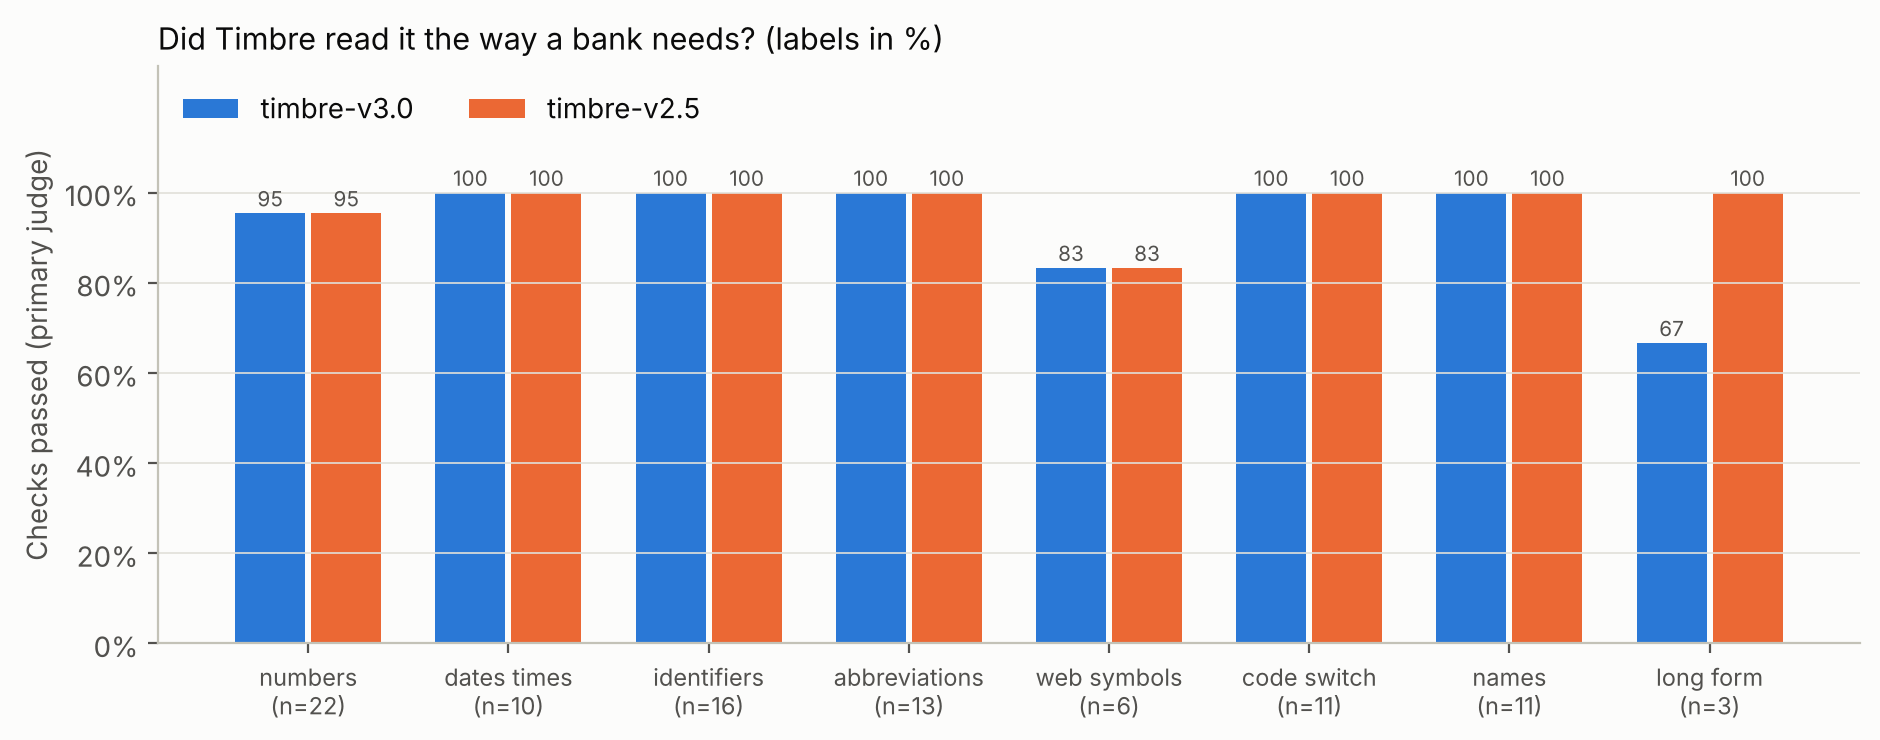

In [14]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
cats = [c for c in CHK_CATS if c in tn_tbl.index and c != "audio_tags"]
xp, w = np.arange(len(cats)), 0.38
for k, m in enumerate(MODELS):
    v = tn_tbl.loc[cats, m].to_numpy()
    ax.bar(xp + (k - 0.5) * w, v, w * 0.92, color=MODEL_COLOR[m], label=m)
    for x_, y_ in zip(xp + (k - 0.5) * w, v):
        if not np.isnan(y_):
            ax.text(x_, y_ + 0.015, f"{y_ * 100:.0f}", ha="center", fontsize=7.5, color=INK2)
ax.set_xticks(xp, [f"{c.replace('_', ' ')}\n(n={int(tn_n.loc[c].iloc[0])})" for c in cats], fontsize=8.5)
ax.set_ylim(0, 1.28); ax.set_yticks([0, .2, .4, .6, .8, 1.0]); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Checks passed (primary judge)")
ax.set_title("Did Timbre read it the way a bank needs? (labels in %)", loc="left", fontsize=11)
ax.legend(loc="upper left", ncols=2); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "reading_checks.png", dpi=160); plt.show()

### 7.3 Intelligibility: round-trip CER
Lower is better. The judge floor row is the same judge on studio human speech, so it is the best a clip can score.

In [15]:
def rt_table(df, by, judge="sarvam"):
    g = df.dropna(subset=[f"chars_{judge}"]).groupby(by)
    return pd.DataFrame({"clips": g.size(), "CER": g[f"cedits_{judge}"].sum() / g[f"chars_{judge}"].sum(),
                         "WER": g[f"wedits_{judge}"].sum() / g[f"words_{judge}"].sum()})


rt_main = main[main.category.isin(CER_CATS)].copy()
rt_main["language"] = rt_main.lang.map(lambda l: l.split("-")[0] if l != "hi-en" else "hinglish")
lang_tbl = pd.concat({j: rt_table(rt_main[rt_main.category == "baseline"], ["language", "model"], j) for j in JUDGES}, axis=1)
floor = anc_score.groupby(["lang", "judge"]).apply(lambda g: g.cedits.sum() / g.chars.sum(), include_groups=False).unstack()
floor.index = floor.index.map(lambda l: l.split("-")[0])
print("Baseline sentences by language (CER and WER per judge):")
display(lang_tbl.style.format("{:.1%}", subset=[c for c in lang_tbl.columns if c[1] in ("CER", "WER")]))
print("Judge floor: CER on studio human speech (IndicTTS Hindi and Tamil, LJ Speech English):")
display(floor.style.format("{:.1%}"))
cat_tbl = pd.concat({j: rt_table(rt_main, ["category", "model"], j) for j in JUDGES}, axis=1)
print("By category:")
display(cat_tbl.style.format("{:.1%}", subset=[c for c in cat_tbl.columns if c[1] in ("CER", "WER")]))

Baseline sentences by language (CER and WER per judge):


Judge floor: CER on studio human speech (IndicTTS Hindi and Tamil, LJ Speech English):


judge,prisma,sarvam
lang,,
en,18.5%,0.0%
hi,3.4%,1.9%
ta,2.5%,0.8%


By category:


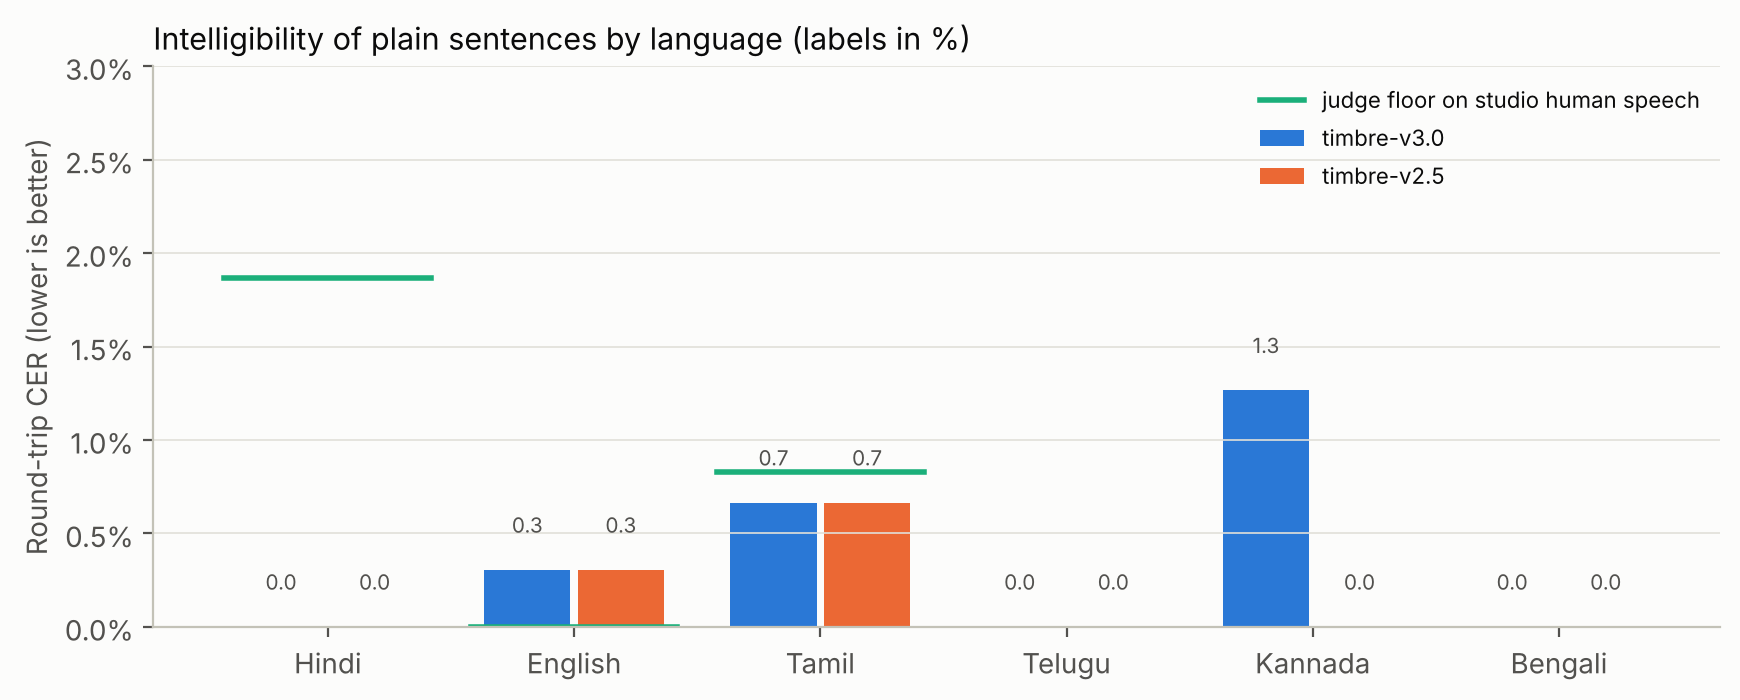

In [16]:
fig, ax = plt.subplots(figsize=(8.8, 3.6))
langs = ["hi", "en", "ta", "te", "kn", "bn"]
lt = lang_tbl["sarvam"].reset_index()
xp, w = np.arange(len(langs)), 0.38
for k, m in enumerate(MODELS):
    v = lt[lt.model == m].set_index("language").reindex(langs).CER.to_numpy()
    ax.bar(xp + (k - 0.5) * w, v, w * 0.92, color=MODEL_COLOR[m], label=m)
    for x_, y_ in zip(xp + (k - 0.5) * w, v):
        if not np.isnan(y_):
            ax.text(x_, y_ + 0.002, f"{y_ * 100:.1f}", ha="center", fontsize=7.5, color=INK2)
for i, lg in enumerate(langs):
    if lg in floor.index:
        ax.plot([i - 0.42, i + 0.42], [floor.loc[lg, "sarvam"]] * 2, color=C_HUMAN, lw=2)
ax.plot([], [], color=C_HUMAN, lw=2, label="judge floor on studio human speech")
ax.set_xticks(xp, ["Hindi", "English", "Tamil", "Telugu", "Kannada", "Bengali"])
ax.set_ylim(0, 0.03)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_ylabel("Round-trip CER (lower is better)")
ax.set_title("Intelligibility of plain sentences by language (labels in %)", loc="left", fontsize=11)
ax.legend(fontsize=8, loc="upper right"); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "roundtrip_cer_by_language.png", dpi=160); plt.show()

In [17]:
print("Code-switched and Roman-script Hinglish, side by side (primary judge):")
display(main[main.category == "code_switch"].pivot_table(index="item", columns="model", values="hyp_sarvam", aggfunc="first")
        .join(items[["text"]]).reindex(columns=["text"] + MODELS))
print("Long-form: duration, words heard vs expected, and whether the last sentence was spoken:")
lf = main[main.category == "long_form"][["model", "item", "chars", "audio_s", "words_sarvam", "wedits_sarvam", "cedits_sarvam", "chars_sarvam"]].copy()
lf["CER"] = lf.cedits_sarvam / lf.chars_sarvam
lf["words heard"] = main.loc[lf.index, "hyp_sarvam"].map(lambda t: len(normalize(t).split()))
lf["last sentence heard"] = lf.apply(lambda r: bool(mchk[(mchk.item == r["item"]) & (mchk.model == r.model) & (mchk.judge == "sarvam")].passed.all()), axis=1)
display(lf[["model", "item", "chars", "audio_s", "words_sarvam", "words heard", "CER", "last sentence heard"]]
        .rename(columns={"words_sarvam": "words expected"}).style.format({"audio_s": "{:.1f}", "CER": "{:.1%}"}).hide(axis="index"))

print("Truncation probe: the Hinglish paragraph synthesized 4 times per model (main run + 3 repeats):")
pr = clip[(clip["item"] == "lf_cs") & clip.group.isin(["main", "probe"])].copy()
pr["words heard"] = pr.hyp_sarvam.map(lambda t: len(normalize(t).split()))
pr["complete"] = pr.job.map(lambda j: bool(checks[(checks.job == j) & (checks.judge == "sarvam")].passed.all()))
display(pr.sort_values(["model", "rep"])[["model", "rep", "audio_s", "words_sarvam", "words heard", "complete"]]
        .rename(columns={"words_sarvam": "words expected"}).style.format({"audio_s": "{:.1f}"}).hide(axis="index"))

Code-switched and Roman-script Hinglish, side by side (primary judge):


,text,timbre-v3.0,timbre-v2.5
item,,,
cs_01,"सर, आपका payment pending है, please आज ही pay कर दीजिए।",सर आपका पेमेंट पेंडिंग है। प्लीज़ आज ही पे कर दीजिए।,सर आपका पेमेंट पेंडिंग है प्लीज़ आज ही पे कर दीजिए।
cs_02,"आपका loan approval process में है, 2 working days लगेंगे।",आपका लोन अप्रूवल प्रोसेस में है दो वर्किंग डेज़ लगेंगे,आपका लोन अप्रूवल प्रोसेस में है दो वर्किंग डेज़ लगेंगे।
cs_03,"मेरा account block हो गया है, please इसे unblock कर दीजिए।",मेरा अकाउंट ब्लॉक हो गया है। प्लीज़ इसे अनब्लॉक कर दीजिए।,मेरा अकाउंट ब्लॉक हो गया है प्लीज इसे अनब्लॉक कर दीजिए।
cs_04,"Aapka payment abhi tak pending hai, kripya aaj hi pay kar dijiye.",आपका पेमेंट अभी तक पेंडिंग है कृपया आज ही पे कर दीजिए।,आपका पेमेंट अभी तक पेंडिंग है कृपया आज ही पे कर दीजिए।
cs_05,"Sir, aapka card dispatch ho gaya hai, do din mein deliver ho jayega.",सर आपका कार्ड डिस्पैच हो गया है। दो दिन में डिलीवर हो जाएगा।,सर आपका कार्ड डिस्पैच हो गया है दो दिन में डिलीवर हो जाएगा।
cs_06,"Main aapki madad kar sakti hoon, bas apna registered mobile number bataiye.",मैं आपकी मदद कर सकती हूँ बस अपना रजिस्टर्ड मोबाइल नंबर बताइए।,मैं ना आपकी मदद कर सकती हूँ बस अपना रजिस्टर्ड मोबाइल नंबर बताइए।


Long-form: duration, words heard vs expected, and whether the last sentence was spoken:


model,item,chars,audio_s,words expected,words heard,CER,last sentence heard
timbre-v3.0,lf_hi,664,45.9,138.000000,138,0.0%,True
timbre-v3.0,lf_en,826,42.2,139.000000,139,0.0%,True
timbre-v3.0,lf_cs,356,6.8,78.000000,26,67.8%,False
timbre-v2.5,lf_hi,664,40.5,138.000000,138,0.0%,True
timbre-v2.5,lf_en,826,37.1,139.000000,139,0.0%,True
timbre-v2.5,lf_cs,356,21.3,78.000000,79,1.9%,True


Truncation probe: the Hinglish paragraph synthesized 4 times per model (main run + 3 repeats):


model,rep,audio_s,words expected,words heard,complete
timbre-v2.5,1,21.3,78.000000,79,True
timbre-v2.5,2,21.0,78.000000,79,True
timbre-v2.5,3,21.1,78.000000,79,True
timbre-v2.5,4,22.1,78.000000,79,True
timbre-v3.0,1,6.8,78.000000,26,False
timbre-v3.0,2,21.3,78.000000,79,True
timbre-v3.0,3,22.5,78.000000,78,True
timbre-v3.0,4,21.4,78.000000,79,True


### 7.4 Phone-line output (8 kHz G.711 μ-law)

In [18]:
tel = clip[clip["item"].isin(TEL_IDS) & clip.group.isin(["main", "telephony"])].copy()
tel_cer = tel.dropna(subset=["chars_sarvam"]).groupby(["model", "fmt"]).apply(
    lambda g: g.cedits_sarvam.sum() / g.chars_sarvam.sum(), include_groups=False).unstack()
tel_chk = checks[checks["item"].isin(TEL_IDS) & checks.group.isin(["main", "telephony"]) & (checks.judge == "sarvam")]
tel_tbl = pd.DataFrame({"CER, 24 kHz WAV": tel_cer["wav24k"], "CER, 8 kHz mu-law": tel_cer["mulaw8k"],
                        "checks passed, 24 kHz": tel_chk[tel_chk.fmt == "wav24k"].groupby("model").passed.mean(),
                        "checks passed, 8 kHz": tel_chk[tel_chk.fmt == "mulaw8k"].groupby("model").passed.mean()})
display(tel_tbl.style.format("{:.1%}"))

,"CER, 24 kHz WAV","CER, 8 kHz mu-law","checks passed, 24 kHz","checks passed, 8 kHz"
model,,,,
timbre-v2.5,0.0%,0.0%,100.0%,100.0%
timbre-v3.0,0.0%,0.0%,100.0%,100.0%


### 7.5 Naturalness: UTMOS22 predicted MOS
UTMOS22 predicts a 1–5 mean opinion score from audio alone. It was trained on English listening tests, so it is used here
to compare like with like (model vs model, voice vs voice), anchored by the same score on studio human recordings in each language.
It is not a substitute for a listening test with the customer's callers.

In [19]:
UTMOS_FILE = RES / "utmos.csv"


def utmos_scores(paths):
    import torch
    from speechmos.utmos22.strong.model import UTMOS22Strong
    have = pd.read_csv(UTMOS_FILE) if UTMOS_FILE.exists() else pd.DataFrame(columns=["path", "utmos"])
    todo = [p for p in paths if p not in set(have.path)]
    if todo:
        torch.set_num_threads(max(1, os.cpu_count() or 1))
        model = UTMOS22Strong()
        model.load_state_dict(torch.hub.load_state_dict_from_url(
            "https://github.com/tarepan/SpeechMOS/releases/download/v1.0.0/utmos22_strong_step7459_v1.pt", map_location="cpu"))
        model.eval()
        new = []
        for p in todo:
            x, _ = librosa.load(ROOT / p, sr=16000)
            x = x[: 20 * 16000]                         # first 20 s is enough and keeps memory flat
            with torch.no_grad():
                new.append(dict(path=p, utmos=float(model(torch.from_numpy(x).unsqueeze(0), 16000))))
        have = pd.concat([have, pd.DataFrame(new)], ignore_index=True)
        have.to_csv(UTMOS_FILE, index=False)
    return have.set_index("path").utmos


wav_paths = jobs.loc[jobs.index.isin(final.index) & (jobs.fmt == "wav24k"), "path"].tolist()
U = utmos_scores(wav_paths + anc.path.tolist())
clip["utmos"] = clip.job.map(jobs.path).map(U)
anc["utmos"] = anc.path.map(U)
mos = clip[(clip.group == "main")].copy()
mos["language"] = mos.lang.map(lambda l: l.split("-")[0] if l != "hi-en" else "hinglish")
mos_tbl = mos.groupby(["language", "model"]).utmos.agg(["mean", "std", "size"]).unstack("model")
anc_mos = anc.groupby(anc.lang.map(lambda l: l.split("-")[0])).utmos.mean()
mos_view = pd.DataFrame({m: mos_tbl[("mean", m)] for m in MODELS})
mos_view["studio human"] = anc_mos
display(mos_view.reindex(["hi", "en", "ta", "te", "kn", "bn", "hinglish"]).style.format("{:.2f}", na_rep=""))
print("Overall mean UTMOS:", mos.groupby("model").utmos.mean().round(2).to_dict(), "| studio human:", round(anc.utmos.mean(), 2))
vo = clip[clip["item"].isin(VOICE_IDS) & clip.group.isin(["main", "voices"])].groupby(["model", "voice"]).utmos.mean()
print("By voice on the same 6 Hindi sentences:")
display(vo.to_frame("mean UTMOS").style.format("{:.2f}"))

,timbre-v3.0,timbre-v2.5,studio human
language,,,
hi,3.22,3.79,4.25
en,3.71,4.14,4.36
ta,2.61,3.17,3.90
te,3.28,4.16,
kn,2.84,3.62,
bn,2.87,3.48,
hinglish,3.22,4.24,


Overall mean UTMOS: {'timbre-v2.5': 3.94, 'timbre-v3.0': 3.41} | studio human: 4.17
By voice on the same 6 Hindi sentences:


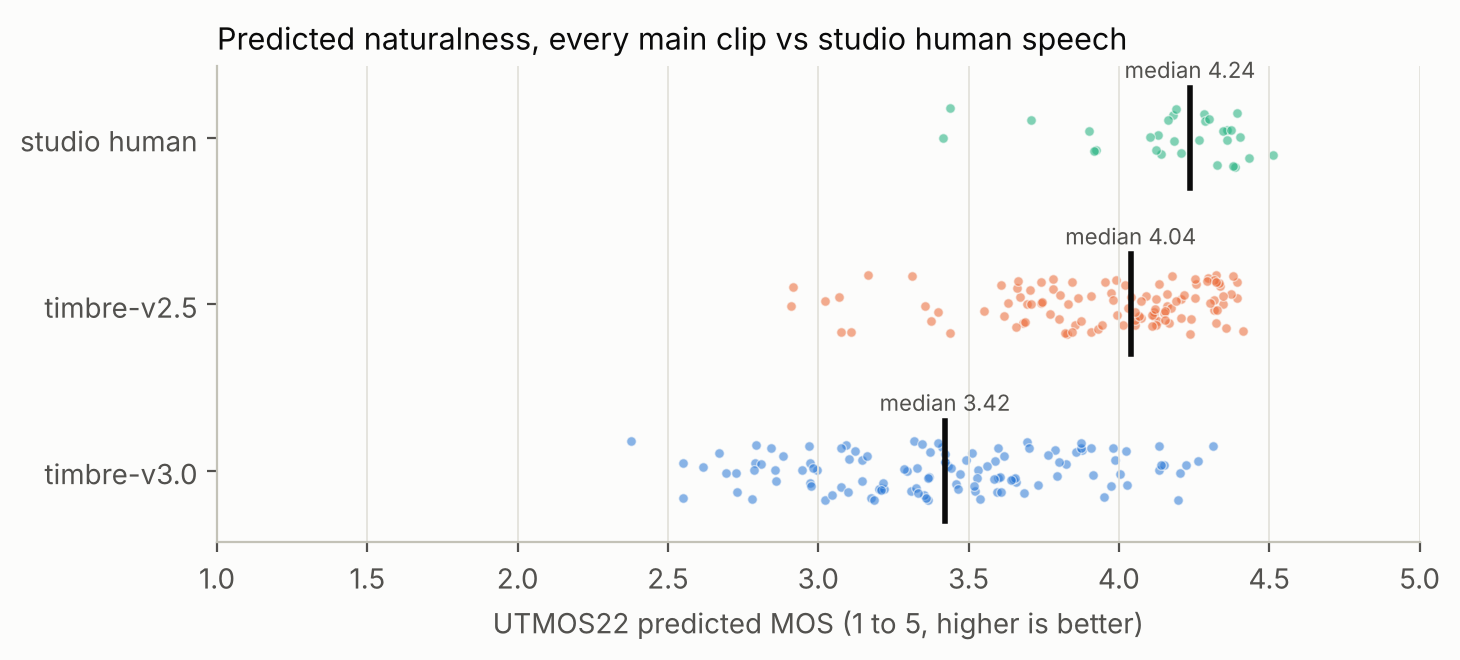

In [20]:
fig, ax = plt.subplots(figsize=(7.4, 3.4))
groups = [("timbre-v3.0", mos[mos.model == "timbre-v3.0"].utmos), ("timbre-v2.5", mos[mos.model == "timbre-v2.5"].utmos),
          ("studio human", anc.utmos)]
for i, (name, v) in enumerate(groups):
    v = v.dropna().to_numpy()
    jit = np.random.default_rng(SEED).uniform(-0.18, 0.18, len(v))
    ax.scatter(v, i + jit, s=12, color=MODEL_COLOR[name], alpha=0.55, edgecolors="#fcfcfb", linewidths=0.5)
    ax.plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color=INK, lw=2)
    ax.text(np.median(v), i + 0.36, f"median {np.median(v):.2f}", ha="center", fontsize=8, color=INK2)
ax.set_yticks(range(3), [g[0] for g in groups]); ax.set_xlim(1, 5)
ax.set_xlabel("UTMOS22 predicted MOS (1 to 5, higher is better)")
ax.set_title("Predicted naturalness, every main clip vs studio human speech", loc="left", fontsize=11)
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(FIG / "utmos.png", dpi=160); plt.show()

### 7.6 Speed: time to first audio and real-time factor

In [21]:
lat = pd.DataFrame(map(json.loads, LAT_FILE.read_text(encoding="utf-8").splitlines()))
lat_ok = lat[(lat.status == 200) & lat.t_first.notna() & (lat.error.fillna("") == "")].copy()
lat_ok["client_ttfa_ms"] = 1000 * (lat_ok.t_first - lat_ok.t0)
lat_ok["server_ttfa_ms"] = 1000 * (lat_ok.t_first - lat_ok.t_start)
lat_ok["stream_rtf"] = (lat_ok.t_done - lat_ok.t_start) / lat_ok.audio_s
print(f"{len(lat_ok)} of {len(lat)} streaming requests succeeded")
q = lambda p: (lambda s: s.quantile(p))
lat_tbl = lat_ok.groupby(["model", "protocol", "length"]).agg(
    runs=("rep", "size"), audio_s=("audio_s", "median"),
    client_ttfa_p50=("client_ttfa_ms", "median"), client_ttfa_p95=("client_ttfa_ms", q(0.95)),
    server_ttfa_p50=("server_ttfa_ms", "median"), server_ttfa_p95=("server_ttfa_ms", q(0.95)),
    stream_rtf_p50=("stream_rtf", "median"))
display(lat_tbl.style.format("{:.0f}", subset=[c for c in lat_tbl.columns if "ttfa" in c]).format("{:.2f}", subset=["audio_s", "stream_rtf_p50"]))
if "t_connect_s" in lat_ok:
    print("WebSocket connect time (TLS + upgrade), median ms:",
          (1000 * lat_ok[lat_ok.protocol == "websocket"].groupby("model").t_connect_s.median()).round(0).to_dict())
rest = clip[(clip.group == "main") & (clip.fmt == "wav24k")].copy()
rest["rest_rtf"] = rest.rest_wall_s / rest.audio_s
print("REST (full file in one response), all main clips:")
display(rest.groupby("model").agg(clips=("job", "size"), total_s_p50=("rest_wall_s", "median"), total_s_p95=("rest_wall_s", q(0.95)),
                                  rtf_p50=("rest_rtf", "median"), rtf_p95=("rest_rtf", q(0.95))).style.format("{:.2f}"))

58 of 60 streaming requests succeeded


WebSocket connect time (TLS + upgrade), median ms: {'timbre-v2.5': 839.0, 'timbre-v3.0': 1091.0}
REST (full file in one response), all main clips:


,clips,total_s_p50,total_s_p95,rtf_p50,rtf_p95
model,,,,,
timbre-v2.5,107.00,1.74,2.26,0.53,0.93
timbre-v3.0,117.00,5.78,8.29,1.56,3.07


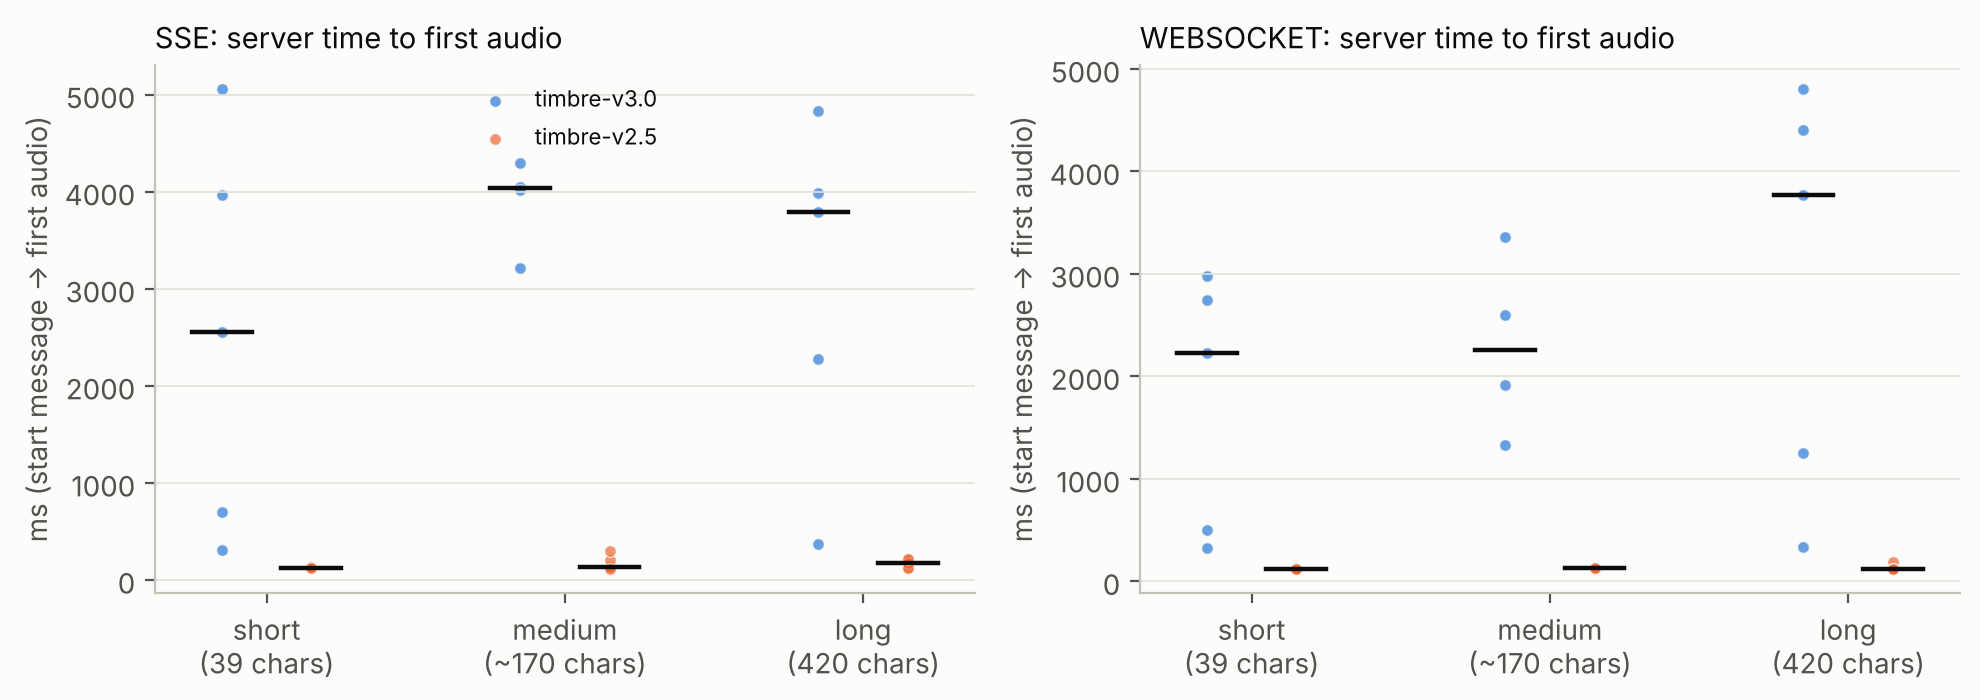

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, proto in zip(axes, ("sse", "websocket")):
    for k, m in enumerate(MODELS):
        d = lat_ok[(lat_ok.model == m) & (lat_ok.protocol == proto)]
        for i, ln in enumerate(["short", "medium", "long"]):
            v = d[d.length == ln].server_ttfa_ms.to_numpy()
            xs_ = np.full(len(v), i + (k - 0.5) * 0.3)
            ax.scatter(xs_, v, s=18, color=MODEL_COLOR[m], alpha=0.7, edgecolors="#fcfcfb", linewidths=0.5,
                       label=m if i == 0 else None)
            if len(v):
                ax.plot([xs_[0] - 0.1, xs_[0] + 0.1], [np.median(v)] * 2, color=INK, lw=1.6)
    ax.set_xticks(range(3), ["short\n(39 chars)", "medium\n(~170 chars)", "long\n(420 chars)"])
    ax.set_title(f"{proto.upper()}: server time to first audio", loc="left", fontsize=10.5)
    ax.set_ylabel("ms (start message → first audio)"); ax.grid(axis="x", visible=False)
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "latency_ttfa.png", dpi=160); plt.show()

### 7.7 Prosody: do questions rise?
Pitch (F0) is tracked with pYIN. The score is the median pitch of the last 25% of voiced frames minus the median of the rest,
in semitones. A yes/no question asked without a question word should rise at the end, and its statement twin should not.

In [23]:
def final_rise(path):
    y, sr = librosa.load(ROOT / path, sr=16000)
    f0, voiced, _ = librosa.pyin(y, fmin=70, fmax=450, sr=sr, frame_length=1024)
    f = f0[voiced & ~np.isnan(f0)]
    if len(f) < 12:
        return np.nan
    k = max(3, len(f) // 4)
    return 12 * np.log2(np.median(f[-k:]) / np.median(f[:-k]))


pros = clip[(clip.category == "prosody") & (clip.group == "main")].copy()
pros["rise_st"] = pros.job.map(jobs.path).map(final_rise)
pros["pair"] = pros["item"].map(items.pair); pros["kind"] = pros["item"].map(items.kind)
pv = pros.pivot_table(index=["model", "pair"], columns="kind", values="rise_st")
pv["question minus statement"] = pv.question - pv.statement
display(pv.style.format("{:+.1f}"))
print("Questions that rise at least 2 semitones more than their statement:",
      pv.groupby(level="model").apply(lambda g: f"{int((g['question minus statement'] >= 2).sum())}/{len(g)}").to_dict())

Questions that rise at least 2 semitones more than their statement: {'timbre-v2.5': '5/5', 'timbre-v3.0': '4/5'}


### 7.8 Audio tags (v3.0)
Each tagged sentence is compared with the same sentence without the tag, on the effect the tag should have.

In [24]:
def sig(path):
    y, sr = sf.read(ROOT / path, dtype="float32")
    fr = int(0.02 * sr); n = len(y) // fr
    e = 10 * np.log10((y[: n * fr].reshape(n, fr) ** 2).mean(1) + 1e-10)
    act = e > e.max() - 35
    idx = np.where(act)[0]
    inner = act[idx[0]: idx[-1] + 1] if len(idx) else act
    gaps, run = [], 0
    for a in inner:
        run = 0 if a else run + 1
        gaps.append(run)
    half = n // 2
    y16 = librosa.resample(y, orig_sr=sr, target_sr=16000)
    f0, voiced, _ = librosa.pyin(y16, fmin=70, fmax=600, sr=16000, frame_length=1024)
    vh = voiced[len(voiced) // 2:]
    return dict(dur=len(y) / sr, rms_db=10 * np.log10((y ** 2).mean() + 1e-10), longest_pause_s=max(gaps or [0]) * 0.02,
                second_half_minus_first_db=e[half:][act[half:]].mean() - e[:half][act[:half]].mean() if act[half:].any() and act[:half].any() else np.nan,
                voiced_frac_2nd_half=float(vh.mean()) if len(vh) else np.nan,
                f0_median=float(np.nanmedian(f0[voiced])) if voiced.any() else np.nan)


tagrows = []
for tid, lg, txt, tag, leak in TAGS:
    for m in MODELS:
        a, c = f"{m}|{VOICE[m][lg]}|wav24k|r1|{tid}", f"{m}|{VOICE[m][lg]}|wav24k|r1|{tid}_ctl"
        if a in final.index:
            sa = sig(jobs.loc[a, "path"]); sc = sig(jobs.loc[c, "path"]) if c in final.index else {}
            leaked = not checks[(checks.job == a) & (checks.judge == "sarvam")].passed.all()
            tagrows.append(dict(model=m, tag=f"<{tag}>", duration_ratio=sa["dur"] / sc["dur"] if sc else np.nan,
                                rms_change_db=sa["rms_db"] - sc["rms_db"] if sc else np.nan,
                                longest_pause_s=sa["longest_pause_s"], control_pause_s=sc.get("longest_pause_s", np.nan),
                                second_half_change_db=sa["second_half_minus_first_db"] - sc.get("second_half_minus_first_db", np.nan),
                                voiced_2nd_half=sa["voiced_frac_2nd_half"], control_voiced_2nd_half=sc.get("voiced_frac_2nd_half", np.nan),
                                pitch_change_st=12 * np.log2(sa["f0_median"] / sc["f0_median"]) if sc else np.nan,
                                tag_read_aloud=leaked, heard=JT.loc[a, "sarvam"] if a in JT.index else ""))
tg = pd.DataFrame(tagrows)
print("Expected effects: <pauses> longer internal pause, <whispers> less voicing in the second half, <shouting> louder and higher,\n"
      "<slow> longer duration, <laugh>/<sigh> extra non-speech sound (longer duration), and no tag name spoken.")
display(tg.style.format({"duration_ratio": "{:.2f}", "rms_change_db": "{:+.1f}", "longest_pause_s": "{:.2f}",
                         "control_pause_s": "{:.2f}", "second_half_change_db": "{:+.1f}", "voiced_2nd_half": "{:.0%}",
                         "control_voiced_2nd_half": "{:.0%}", "pitch_change_st": "{:+.1f}"}, na_rep="").hide(axis="index"))

Expected effects: <pauses> longer internal pause, <whispers> less voicing in the second half, <shouting> louder and higher,
<slow> longer duration, <laugh>/<sigh> extra non-speech sound (longer duration), and no tag name spoken.


model,tag,duration_ratio,rms_change_db,longest_pause_s,control_pause_s,second_half_change_db,voiced_2nd_half,control_voiced_2nd_half,pitch_change_st,tag_read_aloud,heard
timbre-v3.0,,1.22,-0.5,0.54,0.40,+1.4,59%,65%,+1.6,False,Let me check that for you. Found it. Your order ships tomorrow.
timbre-v3.0,,1.07,-1.6,0.14,0.38,+1.2,46%,89%,+0.6,False,Please hold on. Your order is almost ready.
timbre-v3.0,,1.16,+0.7,0.08,0.04,+3.9,68%,74%,+9.0,False,This is a final reminder to pay your dues.
timbre-v3.0,,1.40,-0.4,0.06,0.04,-0.8,59%,76%,-1.5,False,Please note your reference number carefully.
timbre-v3.0,,1.17,-0.5,0.20,0.42,+4.3,77%,85%,-1.4,False,आपका ऑर्डर आ गया है बहुत अच्छा चुनाव किया आपने।
timbre-v2.5,,,,0.24,,,76%,,,False,आपका ऑर्डर आ गया है बहुत अच्छा चुनाव किया आपने।
timbre-v3.0,,1.38,-2.0,0.34,0.42,+0.9,68%,81%,-0.7,False,I understand. These things happen.
timbre-v2.5,,,,0.28,,,75%,,,False,"I understand, these things happen."


### 7.9 Consistency, loudness and signal hygiene

In [25]:
rep = clip[clip["item"].isin(REP_IDS) & clip.group.isin(["main", "repeat"]) & (clip.fmt == "wav24k")]
rep = rep[rep.apply(lambda r: r.voice == VOICE[r.model][r.lang], axis=1)]
cons = rep.groupby(["model", "item"]).agg(runs=("job", "size"), dur_mean=("audio_s", "mean"), dur_cv=("audio_s", lambda s: s.std() / s.mean()))
same = []
for (m, i), g in rep.groupby(["model", "item"]):
    ys = [sf.read(ROOT / jobs.loc[j, "path"], dtype="int16")[0] for j in g.job]
    same.append(dict(model=m, item=i, identical_audio=all(len(y) == len(ys[0]) and np.array_equal(y, ys[0]) for y in ys)))
cons = cons.join(pd.DataFrame(same).set_index(["model", "item"]))
display(cons.style.format({"dur_mean": "{:.2f}", "dur_cv": "{:.1%}"}))


def hygiene(path):
    y, sr = sf.read(ROOT / path, dtype="float32")
    fr = int(0.01 * sr); n = len(y) // fr
    e = 10 * np.log10((y[: n * fr].reshape(n, fr) ** 2).mean(1) + 1e-10)
    act = np.where(e > e.max() - 40)[0]
    return dict(clipped_pct=100 * np.mean(np.abs(y) >= 0.999), peak_dbfs=20 * np.log10(np.abs(y).max() + 1e-9),
                rms_dbfs=10 * np.log10((y ** 2).mean() + 1e-10),
                lead_sil_ms=act[0] * 10 if len(act) else np.nan, trail_sil_ms=(n - 1 - act[-1]) * 10 if len(act) else np.nan)


hy = pd.DataFrame([dict(model=r.model, category=r.category, **hygiene(jobs.loc[r.job, "path"])) for r in clip[(clip.group == "main")].itertuples()])
display(hy.groupby("model").agg(clips=("category", "size"), clipped_clips=("clipped_pct", lambda s: int((s > 0.01).sum())),
                                peak_dbfs_max=("peak_dbfs", "max"), rms_dbfs_median=("rms_dbfs", "median"),
                                rms_dbfs_spread_p5_p95=("rms_dbfs", lambda s: s.quantile(0.95) - s.quantile(0.05)),
                                lead_sil_ms_median=("lead_sil_ms", "median"), trail_sil_ms_median=("trail_sil_ms", "median"),
                                trail_sil_ms_max=("trail_sil_ms", "max")).style.format("{:.1f}"))

,clips,clipped_clips,peak_dbfs_max,rms_dbfs_median,rms_dbfs_spread_p5_p95,lead_sil_ms_median,trail_sil_ms_median,trail_sil_ms_max
model,,,,,,,,
timbre-v2.5,107.0,0.0,-0.0,-16.0,4.4,110.0,160.0,300.0
timbre-v3.0,117.0,0.0,-2.0,-22.8,3.2,30.0,180.0,470.0


## 8 · Findings and recommendation

Numbers below come from the run on 15 November 2026: 286 synthesis jobs, 60 streaming runs and 632 judge transcriptions.
Every number is in the tables above.

| Dimension | Timbre v3.0 | Timbre v2.5 | Read it as |
|---|---|---|---|
| Reading checks passed (amounts, dates, IDs, abbreviations, names) | 95 of 98 (96.9%) | 92 of 94 (97.9%) | both strong, tie |
| Plain-sentence intelligibility, 6 languages (round-trip CER) | 0.0% to 1.3% | 0.0% to 0.7% | both near the judge's own floor |
| First-try success (REST) | 91.9% (136 of 148) | 100% (138 of 138) | v2.5 more reliable |
| Server time to first audio, WebSocket, median | 2.2 to 3.8 s | 121 to 126 ms | v2.5 far faster |
| REST real-time factor, median | 1.56 (slower than real time) | 0.53 | v2.5 faster |
| Predicted naturalness (UTMOS22, studio human = 4.17) | 3.41 (default voice) | 3.94 | depends mostly on the voice |
| Questions that rise at the end | 4 of 5 | 5 of 5 | both fine |
| Audio tags | work, never read aloud | stripped as documented | v3.0 only |

### Where Timbre performs well
* **Text normalization is strong in both models.** Lakh and crore amounts, paise, decimals, percentages, dates, 24-hour times,
  financial years, phone and account numbers, OTPs, PAN, IFSC, Aadhaar, vehicle plates, honorifics (`Dr.` → "Doctor"/"डॉक्टर"),
  units and initialisms were read the way Gnani's guide says in almost every case. For example ₹2,50,000 became "दो लाख पचास हज़ार रुपये",
  and `SBIN0001234` became "S B I N zero zero zero one two three four".
* **Plain speech is fully intelligible in all six languages tested** (Hindi, English, Tamil, Telugu, Kannada, Bengali). Round-trip CER
  is 1.3% or lower, in the same range the judge gets on studio recordings of real speakers (0.0% to 1.9%).
* **Code-switching works, including Hinglish typed in Roman script.** "Aapka payment abhi tak pending hai" was spoken as Hindi
  with English loanwords, and all 11 code-switch checks passed on both models.
* **Phone output is safe.** Requesting 8 kHz G.711 μ-law directly gave the same intelligibility and reading accuracy as 24 kHz audio.
* **v2.5 is fast and dependable.** Server time to first audio is 120–180 ms on both streaming APIs, every request succeeded first time,
  and repeated runs give the same duration.
* **v3.0 audio tags do what they say.** No tag was ever read aloud. `<whispers>` cut the voiced share of the second half from 89% to 46%,
  `<shouting>` raised pitch by 9 semitones, `<slow>` stretched the line by 40%, and `<sigh>`/`<laugh>` added 17% to 38% of non-speech sound.
  `<pauses>` had the weakest effect (longest pause 0.54 s against 0.40 s without the tag).

### Where Timbre struggles
* **v3.0 is too slow for live conversation in this test.** From the server's own `start` message to the first audio byte, the
  median was 2.2 to 4.0 s depending on protocol and length, with a p95 near 4.8 s. Gnani's launch material advertises first audio in
  under 200 ms. The fastest v3.0 runs here took 300–500 ms, so the model can be quick, but most requests waited seconds. The spread
  looks like queueing or capacity limits rather than synthesis speed. That needs to be re-measured on a production account from an India region.
* **v3.0 sometimes fails silently.** 11 of 148 first attempts returned HTTP 200 with an empty WAV, each after about 5.7 s, which looks
  like a server-side timeout. One returned HTTP 500 and 2 of 30 streaming requests ended in `synthesis_error`. Worse, one of four runs of the
  same Hinglish paragraph came back complete-looking but cut after the second sentence (6.8 s instead of about 21 s, 26 of 78 words).
  A client that does not check the audio would play silence or half a message. v2.5 had none of these problems.
* **Two reading bugs affect both models.** "8.5% per annum" lost the words "per annum" entirely on both models, as both judges confirm.
  v3.0 also misread `www.gov.in` (heard as "www dot w dot in"). v2.5 spells the local part of an email letter by letter ("s u p p o r t"),
  which Gnani's guide documents but which sounds unnatural.
* **Repeated-digit OTPs.** v2.5 reads `448822` in English as "double four double eight double two", which the guide lists as a known
  limitation. Some callers will type that wrong. v3.0 and all Hindi readings were plain digit by digit.
* **v3.0's default voice scores low on naturalness.** On the same six Hindi sentences, v3.0 Shivani scored 3.05 while v3.0 Tarika scored
  4.26 and Avinash 3.99. The v2.5 voices scored 3.82 to 4.24. Most of v3.0's lower overall score comes from the voice used for the main run.
* **v3.0 output is about 7 dB quieter** (median RMS −22.8 dBFS against −16.0 dBFS). Mixed into a call next to v2.5 prompts or human
  agents, it would sound distant unless normalized.

### Reading the conflicting results
* **Naturalness vs reliability.** UTMOS rewards v2.5 overall, but the voice comparison shows the gap is mostly the voice, not the model.
  v3.0 with Tarika matches the best v2.5 voice. The deciding factors for a contact center are latency and silent failures, and there
  v2.5 is clearly ahead today.
* **"Intelligible" is not the same as "correct".** Every truncated, dropped or misread item above was perfectly clear speech. Only the
  reading checks caught them, which is why they carry more weight than round-trip CER in this evaluation.
* **Is the judge biased?** Gnani's own Prisma, used as a second judge, passed slightly fewer checks than Sarvam (95.8% vs 97.4%) and
  agreed on 97.4% of them. There is no sign that Gnani's ASR is kinder to Gnani's TTS.

### Recommendation for a contact-center customer
1. **Use Timbre v2.5 for live voice agents today.** It is fast (about 120 ms to first audio on the server), it never failed, and its
   number and ID reading is as good as v3.0's. Pick the voice by listening test, with Urmila and Deepak as strong Hindi starting points.
2. **Use Timbre v3.0 for pre-generated, expressive audio**: IVR prompts, payment reminders, notifications and e-learning, where
   a few seconds of latency do not matter and audio tags add value. Choose a voice like Tarika or Avinash, not the default.
3. **Re-test v3.0 latency before using it live.** Run section 3 on the customer's production account from an Indian region, under
   their expected concurrency. If first audio stays above 1 s, keep it out of real-time turns.
4. **Validate every response in the client, whichever model.** Reject audio shorter than about 0.1 s and retry. Compare duration with
   the text length to catch truncation: normal speech here ran at 11 to 23 characters per second, and the truncated clip at 52,
   so a ceiling of about 30 flags it. Normalize loudness before playback.
5. **Prepare risky text.** Write "8.5 percent per year" instead of "8.5% per annum", spell out URLs on v3.0, and send OTPs with
   spaces or as words if "double four" is not acceptable.
6. **Request 8 kHz μ-law directly for SIP calls.** It costs nothing in intelligibility or reading accuracy and saves a resampling step.

### Limitations
* Round-trip scoring uses an ASR as the listener. A strong ASR can recover a slightly mispronounced word, so mispronunciations are
  under-counted. English heteronyms (read/read, live/live) cannot be judged this way at all and were left out.
* UTMOS22 was trained on English listening tests. It is used here for comparisons within a language, anchored on studio speech, and does
  not replace a listening test with the customer's callers.
* Each category has 5 to 22 checks, so one item moves a pass rate by several points.
* Latency was measured from outside India on a free-credit account allowing one request at a time, during one afternoon. Concurrency was not tested.